# Visualization & Baseline Model

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## Load the data

In [ ]:
df = pd.read_csv("ai_jobs_salaries_clean.csv")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 71,913 rows x 17 columns


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN


## Data dictionary — what every column means

| Column | Meaning |
|---|---|
| `work_year` | Calendar year the salary record refers to (2020–2025) |
| `experience_level` | Seniority code: `EN`=Entry, `MI`=Mid, `SE`=Senior, `EX`=Executive |
| `employment_type` | `FT`=Full-time, `PT`=Part-time, `CT`=Contract, `FL`=Freelance |
| `job_title` | Free-text job title as originally posted (422 distinct values) |
| `salary` | Salary in the employee's local currency |
| `salary_currency` | ISO currency code for `salary` |
| `salary_in_usd` | Salary converted to USD — **this is our modeling target** |
| `employee_residence` | Country of residence of the employee (ISO alpha-2) |
| `remote_ratio` | % of work done remotely: 0 = on-site, 50 = hybrid, 100 = fully remote |
| `company_location` | Country where the hiring company is based (ISO alpha-2) |
| `company_size` | `S`=Small, `M`=Medium, `L`=Large |
| `experience_level_label`, `employment_type_label`, `work_mode` | Human-readable duplicates of the coded columns above |
| `salary_outlier_flag` | Boolean flag marking rows identified as salary outliers |
| `role_family` | A cleaned, 11-category grouping of `job_title` (e.g. Data Scientist, ML Engineer) |
| `isco_group_hint` | A rough mapping from `role_family` to a broad ILO/ISCO-08 occupational category — see the dedicated section below |

### `isco_group_hint`

This column connects some of our job roles to occupational categories from the ILO's Generative AI and Jobs paper by Gmyrek et al. (2025) (International Standard Classification of Occupations, 2008). The paper looks at how much different jobs may be affected by generative AI.

The researchers gave occupations an exposure score from 0 to 1. A higher score means more of the job's tasks could potentially be done or helped by generative AI. They also grouped jobs into different exposure levels based on their scores and how consistently their tasks are affected.

Only 5 of our 11 role_family groups have a matching `isco_group_hint`, covering about 44% of the records. The other role groups were not matched to an ISCO-08 category in the dataset.

In [ ]:
iso_counts = df["isco_group_hint"].value_counts(dropna=False)
print(iso_counts)
print()
print("Which role_family maps to which isco_group_hint:")
print(df.dropna(subset=["isco_group_hint"]).groupby("isco_group_hint")["role_family"].value_counts())

isco_group_hint
NaN                                                           40540
Software and applications developers                          12475
Business services and administration managers                  8335
Mathematicians, actuaries and statisticians                    7216
Physical and earth science professionals                       2852
Information and communications technology service managers      495
Name: count, dtype: int64

Which role_family maps to which isco_group_hint:
isco_group_hint                                             role_family       
Business services and administration managers               Data Analyst          8335
Information and communications technology service managers  Analytics Manager      495
Mathematicians, actuaries and statisticians                 Data Scientist        7216
Physical and earth science professionals                    Research Scientist    2852
Software and applications developers                        Data Engineer

Each populated `isco_group_hint` value corresponds almost 1-to-1 with a single `role_family` (e.g. every `Data Scientist` row is tagged `Mathematicians, actuaries and statisticians`). So `isco_group_hint` doesn't add new information beyond `role_family` for rows where it's populated, its real value is as a bridge to the ILO paper's exposure scores, not as a standalone predictor.

## Missing values

In [ ]:
missing = pd.DataFrame({
    "n_missing": df.isnull().sum(),
    "pct_missing": (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values("n_missing", ascending=False)
missing[missing["n_missing"] > 0]

,n_missing,pct_missing
isco_group_hint,40540,56.37


`isco_group_hint` is the only column with missing values (~56% missing), consistent with it only covering 5 of the 11 role families. Every other column is fully populated, so no imputation is needed elsewhere.

## Variable balance

In [ ]:
cat_cols = ["experience_level", "employment_type", "company_size", "remote_ratio",
            "work_mode", "role_family", "work_year", "salary_outlier_flag"]

for c in cat_cols:
    print(f"--- {c} ---")
    print((df[c].value_counts(normalize=True) * 100).round(2).to_string())
    print()

--- experience_level ---
experience_level
SE    52.43
MI    32.53
EN    11.09
EX     3.95

--- employment_type ---
employment_type
FT    98.96
CT     0.53
PT     0.49
FL     0.02

--- company_size ---
company_size
M    97.49
L     2.21
S     0.30

--- remote_ratio ---
remote_ratio
0      75.20
100    24.34
50      0.45

--- work_mode ---
work_mode
On-site    75.20
Remote     24.34
Hybrid      0.45

--- role_family ---
role_family
Other / Unclassified    56.37
Data Analyst            11.59
Data Engineer           10.08
Data Scientist          10.03
ML Engineer              5.06
Research Scientist       3.97
AI Engineer              1.68
Analytics Manager        0.69
AI Architect             0.30
Computer Vision          0.19
NLP                      0.03

--- work_year ---
work_year
2025    53.23
2024    38.50
2023     6.31
2022     1.55
2021     0.30
2020     0.10

--- salary_outlier_flag ---
salary_outlier_flag
False    97.56
True      2.44



- `experience_level` is imbalanced — Senior (52%) dominates, Executive is rare (4%)
- `employment_type` is heavily imbalanced — 99% Full-time
- `company_size` is heavily imbalanced — 97% Medium
- `remote_ratio` is imbalanced — On-site (75%) and Remote (24%) dominate; Hybrid is under 1%
- `role_family` is imbalanced — 56% is "Other / Unclassified"
- `work_year` is skewed toward recent years — 2024–2025 alone make up ~92% of rows
- `salary_outlier_flag` is imbalanced by design — only ~2.4% are flagged

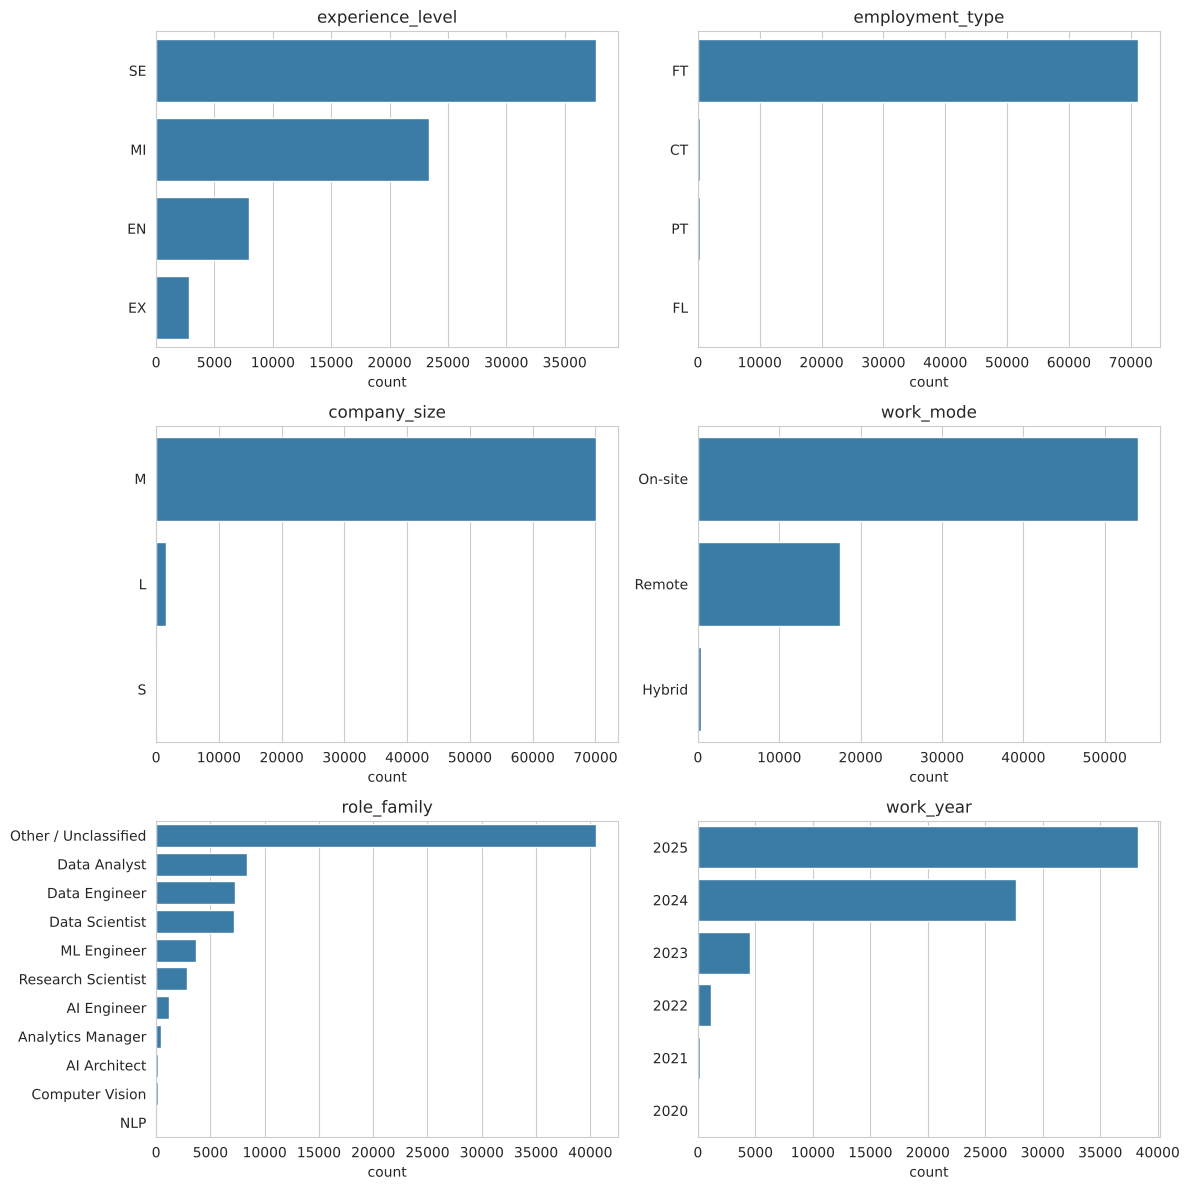

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.ravel()
plot_cols = ["experience_level", "employment_type", "company_size", "work_mode", "role_family", "work_year"]
for ax, c in zip(axes, plot_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=order, ax=ax, color="#2980b9")
    ax.set_title(c)
    ax.set_xlabel("count")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Most bars are dominated by one or two categories, with long tails of rare ones (Contract/Freelance/Part-time, Small/Large company size, Executive level).

## Salary distribution

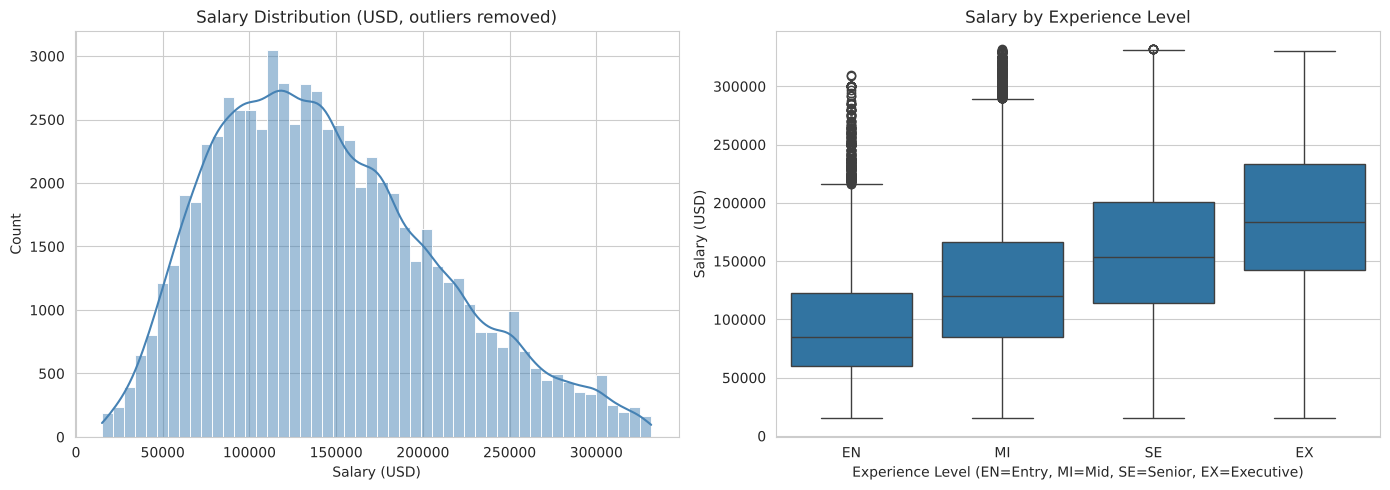

count     71913.000000
mean     151161.252625
std       77329.594122
min       15000.000000
25%       96000.000000
50%      138750.000000
75%      190315.000000
max      800000.000000
Name: salary_in_usd, dtype: float64
Skewness: 1.48


In [ ]:
# I used an outlier-free view (df_clean) only for cleaner visualization.
# salary_outlier_flag is NOT used as a modeling feature later (see leakage section) —
# here it's purely a plotting convenience so extreme values don't compress the histogram.
df_clean = df[df["salary_outlier_flag"] == False].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean["salary_in_usd"], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Salary Distribution (USD, outliers removed)")
axes[0].set_xlabel("Salary (USD)")

sns.boxplot(data=df_clean, x="experience_level", y="salary_in_usd", ax=axes[1],
            order=["EN", "MI", "SE", "EX"])
axes[1].set_title("Salary by Experience Level")
axes[1].set_xlabel("Experience Level (EN=Entry, MI=Mid, SE=Senior, EX=Executive)")
axes[1].set_ylabel("Salary (USD)")

plt.tight_layout()
plt.show()

print(df["salary_in_usd"].describe())
print("Skewness:", df["salary_in_usd"].skew().round(3))

- The salary distribution is right-skewed with a long tail of high earners, typical of salary data, and the reason we log-transform in some later analyses.
- Salary rises clearly and monotonically with experience level: Entry-level salaries cluster lowest, Executive-level highest, with each step up in seniority also widening the spread (more variance in how senior roles are paid).

## Average salary by role family

                          mean    median  count
role_family                                    
AI Architect          192781.0  185000.0    199
Research Scientist    177687.0  173366.0   2642
ML Engineer           176789.0  171080.0   3460
Analytics Manager     168747.0  161400.0    459
Computer Vision       161895.0  170000.0    134
AI Engineer           154529.0  147500.0   1165
Data Scientist        147433.0  140109.0   7102
Other / Unclassified  146617.0  138500.0  39498
Data Engineer         141937.0  135000.0   7168
NLP                   134649.0  150000.0     19
Data Analyst          107661.0   99200.0   8313


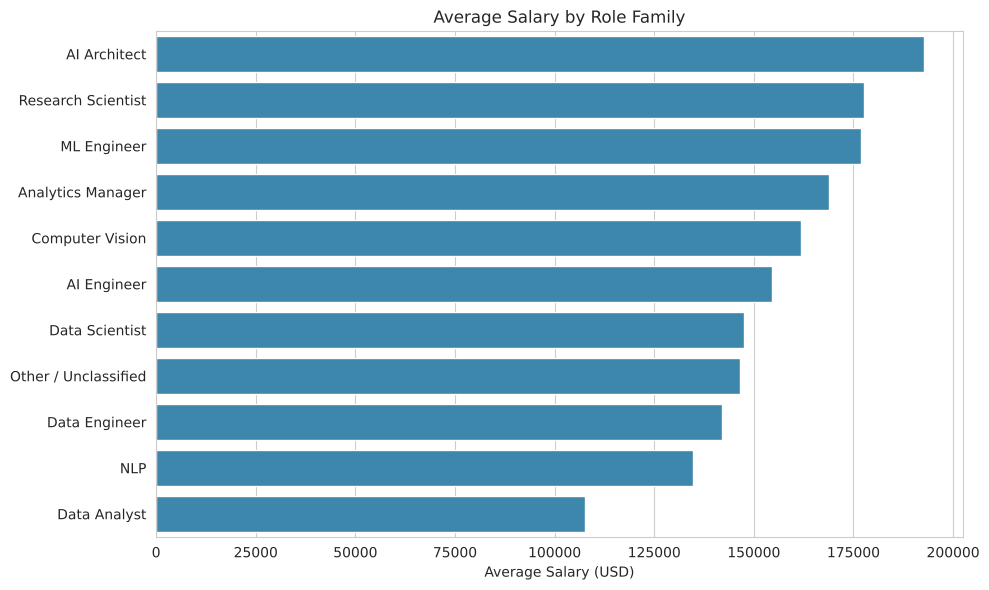

In [ ]:
role_salary = df_clean.groupby("role_family")["salary_in_usd"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False)
print(role_salary.round(0))

plt.figure(figsize=(10, 6))
sns.barplot(data=df_clean, y="role_family", x="salary_in_usd",
            order=role_salary.index, estimator="mean", errorbar=None, color="#2b8cbe")
plt.title("Average Salary by Role Family")
plt.xlabel("Average Salary (USD)")
plt.ylabel("")
plt.tight_layout()
plt.show()

Management and architect-track roles (AI Architect, Analytics Manager) sit at the top, core ML/research roles (Research Scientist, ML Engineer, Data Scientist) sit in the upper-middle, and Data Analyst sits lowest among the classified roles — consistent with typical seniority and specialization patterns in the field. "Other / Unclassified" (56% of the data) sits close to the middle, which is expected since it's a mixed bag of many different job titles rather than a single role type.

## Correlation between numeric variables

               work_year  salary_in_usd  remote_ratio
work_year          1.000          0.018        -0.100
salary_in_usd      0.018          1.000         0.002
remote_ratio      -0.100          0.002         1.000


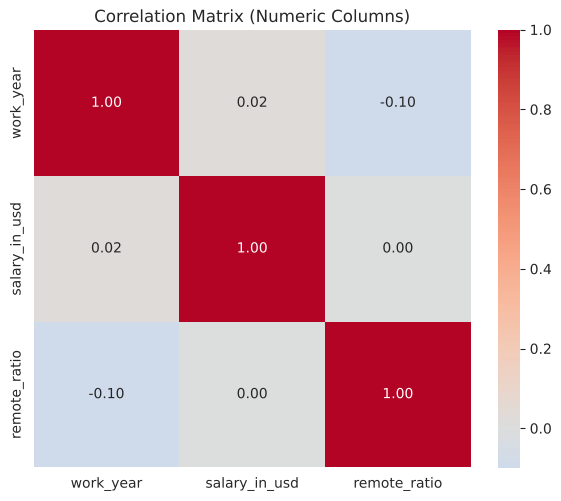

In [ ]:
numeric_cols = ["work_year", "salary_in_usd", "remote_ratio"]
corr_matrix = df_clean[numeric_cols].corr()
print(corr_matrix.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f", square=True)
plt.title("Correlation Matrix (Numeric Columns)")
plt.tight_layout()
plt.show()

None of the three numeric columns are strongly correlated with each other or with salary in a linear sense (all correlations are weak). That doesn't mean `work_year` or `remote_ratio` are useless, their relationship with salary is more about differences between categories (e.g. On-site vs Remote, 2020 vs 2025) than a straight linear trend, which the boxplots below capture better than a correlation coefficient can.

## Salary by work arrangement

                           mean    median  count
work_arrangement                                
Hybrid             78841.086420   68276.0    324
On-site           144843.003576  136000.0  52570
Remote            145486.145207  140000.0  17265


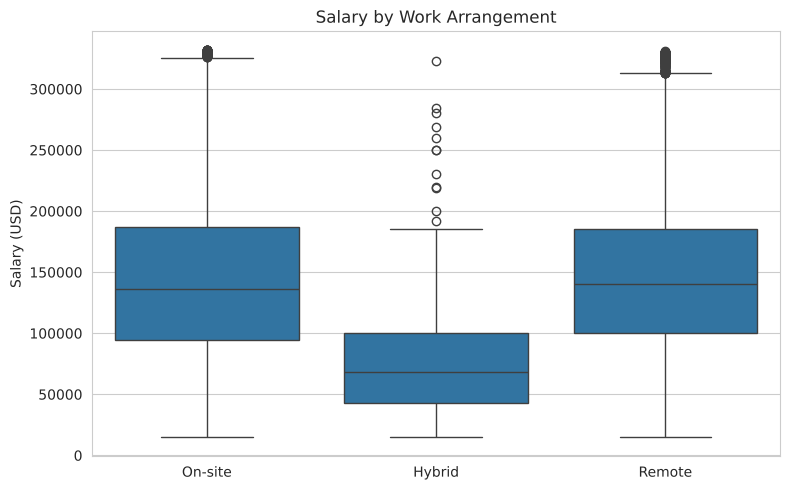

In [ ]:
remote_labels = {0: "On-site", 50: "Hybrid", 100: "Remote"}
df_clean["work_arrangement"] = df_clean["remote_ratio"].map(remote_labels)

print(df_clean.groupby("work_arrangement")["salary_in_usd"].agg(["mean", "median", "count"]))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="work_arrangement", y="salary_in_usd", order=["On-site", "Hybrid", "Remote"])
plt.title("Salary by Work Arrangement")
plt.xlabel("")
plt.ylabel("Salary (USD)")
plt.tight_layout()
plt.show()

In [ ]:
hybrid_data = df_clean[df_clean["work_arrangement"] == "Hybrid"]
print("=== Top role families in Hybrid ===")
print(hybrid_data["role_family"].value_counts().head(5))
print("\n=== Top countries in Hybrid ===")
print(hybrid_data["company_location"].value_counts().head(5))
print("\n=== Experience levels in Hybrid ===")
print(hybrid_data["experience_level"].value_counts())

=== Top role families in Hybrid ===
role_family
Data Scientist          99
Other / Unclassified    69
Data Analyst            45
Data Engineer           42
ML Engineer             30
Name: count, dtype: int64

=== Top countries in Hybrid ===
company_location
US    54
GB    34
DE    30
FR    29
IN    24
Name: count, dtype: int64

=== Experience levels in Hybrid ===
experience_level
MI    121
EN    105
SE     87
EX     11
Name: count, dtype: int64


Hybrid pays noticeably less on average (~\$79K) than On-site or Remote (~\$144–145K each), but this is almost certainly because Hybrid is a tiny group (only ~324 rows), skewed toward lower-paying roles and Entry/Mid-level experience, with very few Executives. In other words, Hybrid isn't underpaid because it's hybrid, the group happens to be made up of the kinds of roles and seniority levels that pay less anyway.

## Salary trends over time, by role family

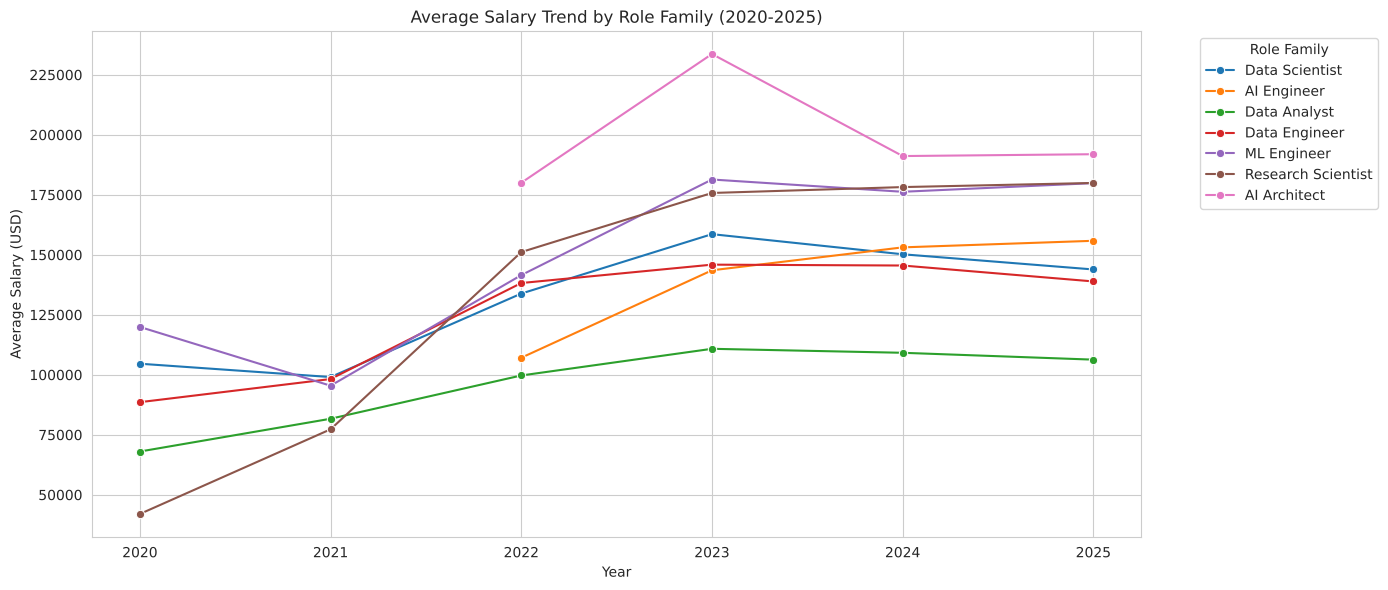

In [ ]:
key_roles = ["AI Architect", "Research Scientist", "ML Engineer", "AI Engineer",
             "Data Scientist", "Data Analyst", "Data Engineer"]
trend_data = df_clean[df_clean["role_family"].isin(key_roles)]

plt.figure(figsize=(14, 6))
sns.lineplot(data=trend_data, x="work_year", y="salary_in_usd", hue="role_family",
             estimator="mean", errorbar=None, marker="o")
plt.title("Average Salary Trend by Role Family (2020-2025)")
plt.xlabel("Year")
plt.ylabel("Average Salary (USD)")
plt.legend(title="Role Family", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Note on scope: I deliberately restrict this trend view to the 7 explicitly classified role families and exclude "Other / Unclassified." Since that catch-all bucket mixes ~330 different job titles, a year-over-year "trend" for it would really just reflect which titles happened to be posted that year.

Most classified roles show a generally rising average salary from 2020 to 2025, with more visible year-to-year swings in the earliest years, expected, since 2020–2022 have far fewer records and small samples are noisier.

## Work arrangement mix over time

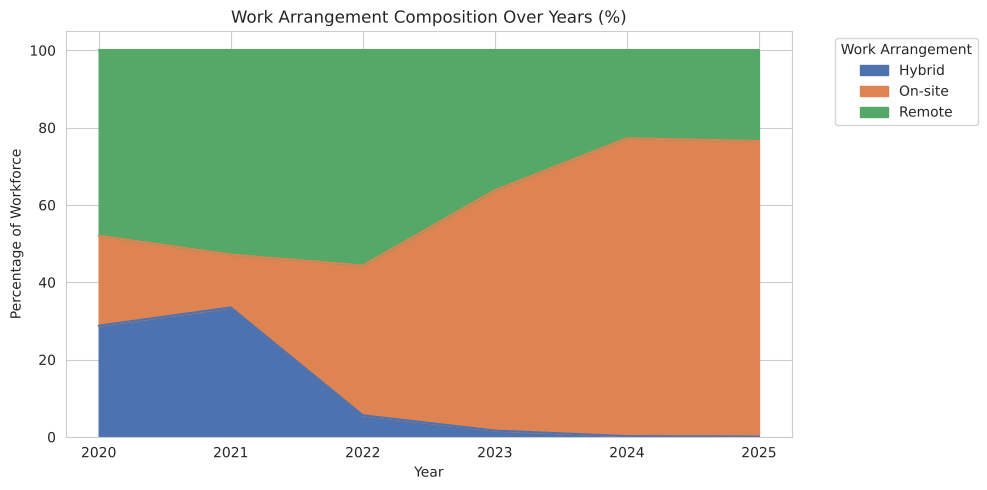

In [ ]:
plt.figure(figsize=(10, 5))
work_mode_trend = pd.crosstab(df_clean["work_year"], df_clean["work_arrangement"], normalize="index") * 100
work_mode_trend.plot(kind="area", stacked=True, ax=plt.gca(), color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("Work Arrangement Composition Over Years (%)")
plt.xlabel("Year")
plt.ylabel("Percentage of Workforce")
plt.legend(title="Work Arrangement", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

The share of fully On-site roles grows sharply in the later years while Remote's share shrinks,a visible pullback from the remote-heavy hiring seen right after 2020–2021. Hybrid stays a thin sliver throughout, never becoming a major category.

## `isco_group_hint` and AI exposure scores

Here I use the exposure scores from the ILO paper, found on pages 48–52. The scores are averaged across the relevant 4-digit ISCO-08 occupations for each of our five isco_group_hint categories.

Recall: higher score = greater estimated potential for generative-AI task automation within that occupation.

In [ ]:
# Approximate exposure scores (0-1 scale), averaged from Gmyrek et al. (2025), Table A1,
# over the 4-digit ISCO-08 occupations underlying each isco_group_hint category.
gmyrek_scores = {
    'Information and communications technology service managers': 0.440,
    'Mathematicians, actuaries and statisticians': 0.561,
    'Software and applications developers': 0.527,
    'Business services and administration managers': 0.419,
    'Physical and earth science professionals': 0.411,
}

df["gmyrek_exposure_score"] = df["isco_group_hint"].map(gmyrek_scores)
print(df["gmyrek_exposure_score"].value_counts(dropna=False))
print(f"\nMatched: {df['gmyrek_exposure_score'].notna().sum()} / {df['isco_group_hint'].notna().sum()} mapped rows")

gmyrek_exposure_score
NaN      40540
0.527    12475
0.419     8335
0.561     7216
0.411     2852
0.440      495
Name: count, dtype: int64

Matched: 31373 / 31373 mapped rows


                                                    mean_salary  \
isco_group_hint                                                   
Physical and earth science professionals               195300.2   
Business services and administration managers          108602.0   
Information and communications technology servi...     185237.6   
Software and applications developers                   160638.7   
Mathematicians, actuaries and statisticians            151556.6   

                                                    exposure_score      n  
isco_group_hint                                                            
Physical and earth science professionals                       0.4   2852  
Business services and administration managers                  0.4   8335  
Information and communications technology servi...             0.4    495  
Software and applications developers                           0.5  12475  
Mathematicians, actuaries and statisticians                    0.6   7216 

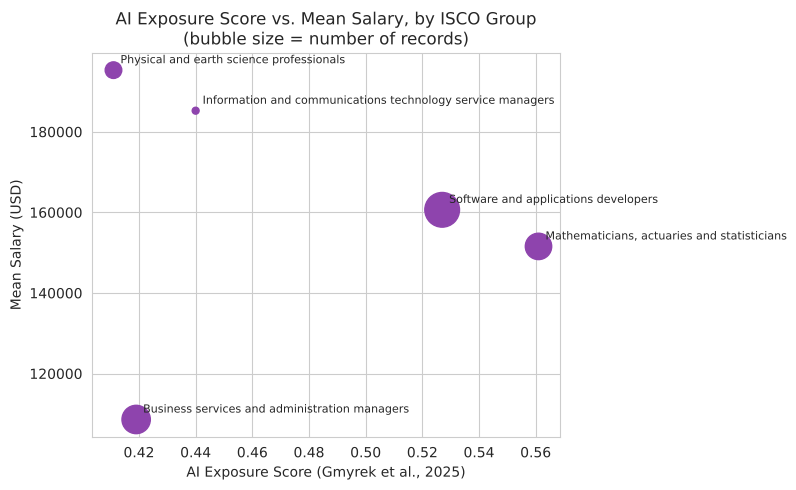

In [ ]:
exposure_salary = (df.dropna(subset=["gmyrek_exposure_score"])
                      .groupby("isco_group_hint")
                      .agg(mean_salary=("salary_in_usd", "mean"),
                           exposure_score=("gmyrek_exposure_score", "first"),
                           n=("salary_in_usd", "count"))
                      .sort_values("exposure_score"))
print(exposure_salary.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(exposure_salary["exposure_score"], exposure_salary["mean_salary"], s=exposure_salary["n"]/20, color="#8e44ad")
for label, row in exposure_salary.iterrows():
    ax.annotate(label, (row["exposure_score"], row["mean_salary"]), fontsize=8, xytext=(5,5), textcoords="offset points")
ax.set_xlabel("AI Exposure Score (Gmyrek et al., 2025)")
ax.set_ylabel("Mean Salary (USD)")
ax.set_title("AI Exposure Score vs. Mean Salary, by ISCO Group\n(bubble size = number of records)")
plt.tight_layout()
plt.show()

Across the 5 groups, there is no clear relationship between AI exposure and average salary. The results are only exploratory due to the small number of groups, but they show how the dataset can be combined with external research like the ILO paper for further analysis.

## Data leakage audit

Before modeling, we check whether any column is a duplicate or downstream derivative of another column

In [ ]:
print("salary == salary_in_usd?", df["salary"].equals(df["salary_in_usd"]))
usd_rows = df[df["salary_currency"] == "USD"]
print("For USD-currency rows, salary == salary_in_usd for",
      round((usd_rows["salary"] == usd_rows["salary_in_usd"]).mean() * 100, 1), "% of rows")
print()
print(df.groupby("salary_outlier_flag")["salary_in_usd"].describe())

salary == salary_in_usd? False
For USD-currency rows, salary == salary_in_usd for 100.0 % of rows

                       count           mean           std       min       25%  \
salary_outlier_flag                                                             
False                70159.0  144696.468122  64832.364871   15000.0   95000.0   
True                  1754.0  409748.946978  92242.103181  332000.0  350000.0   

                          50%       75%       max  
salary_outlier_flag                                
False                136700.0  185800.0  331640.0  
True                 376000.0  429415.0  800000.0  


Findings:
 - salary and salary_currency leak the target because they can directly reproduce salary_in_usd → drop both.
 - salary_outlier_flag appears to be calculated from salary_in_usd → drop it.
 - experience_level_label, employment_type_label, and work_mode duplicate existing variables → drop them.
 - job_title has 422 categories and is largely captured by role_family → drop job_title, keep role_family.
 - isco_group_hint is ~56% missing and closely overlaps with role_family → drop it from the model.

### Columns going into the model
Target: `salary_in_usd` (binned into tiers)
Features: `work_year`, `experience_level`, `employment_type`, `employee_residence`, `remote_ratio`, `company_location`, `company_size`, `role_family`


In [ ]:
drop_cols = ["salary", "salary_currency", "salary_outlier_flag",
             "experience_level_label", "employment_type_label", "work_mode",
             "job_title", "isco_group_hint", "gmyrek_exposure_score"]
model_df = df.drop(columns=drop_cols)
print("Modeling columns:", list(model_df.columns))

Modeling columns: ['work_year', 'experience_level', 'employment_type', 'salary_in_usd', 'employee_residence', 'remote_ratio', 'company_location', 'company_size', 'role_family']


## 13. Baseline model — predicting a salary tier

Since salary_in_usd is a continuous value, accuracy, precision, recall, and F1 are not directly applicable because they are classification metrics. To use these metrics, I turn salary prediction into a classification problem by dividing salaries into four quartile-based tiers: Low, Lower-Mid, Upper-Mid, and High.
This keeps the groups roughly balanced at 25% each. Because each row is an independent job record, we use a random train/test split.
To prevent test-set information from affecting the results, we calculate the quartile boundaries using only the training data and then apply those same boundaries to the test data.

In [ ]:
X = model_df.drop(columns=["salary_in_usd"])
y_raw = model_df["salary_in_usd"]

X_train, X_test, y_train_raw, y_test_raw = train_test_split(X, y_raw, test_size=0.2, random_state=42)

# Define quartile tiers using TRAIN data only, then apply the same boundaries to test
y_train_binned, bin_edges = pd.qcut(y_train_raw, q=4, labels=["Low", "Lower-Mid", "Upper-Mid", "High"], retbins=True)

# Apply train-derived edges to the test set; clip so out-of-range test values fall into the end bins
bin_edges_applied = bin_edges.copy()
bin_edges_applied[0] = -np.inf
bin_edges_applied[-1] = np.inf
y_test_binned = pd.cut(y_test_raw, bins=bin_edges_applied, labels=["Low", "Lower-Mid", "Upper-Mid", "High"])

y_train = y_train_binned
y_test = y_test_binned

print("Quartile boundaries (from training data, USD):", bin_edges.round(0).tolist())
print()
print("Train class balance:")
print(y_train.value_counts(normalize=True).round(3))
print()
print("Test class balance:")
print(y_test.value_counts(normalize=True).round(3))

Quartile boundaries (from training data, USD): [15000.0, 96000.0, 138750.0, 190200.0, 800000.0]

Train class balance:
salary_in_usd
Low          0.25
High         0.25
Upper-Mid    0.25
Lower-Mid    0.25
Name: proportion, dtype: float64

Test class balance:
salary_in_usd
High         0.251
Lower-Mid    0.251
Upper-Mid    0.249
Low          0.249
Name: proportion, dtype: float64


The quartile tiers are, by construction, almost exactly balanced in the training set (~25% each), and applying those same boundaries to the test set keeps it close to balanced too, confirming a plain random split works fine here without needing extra stratification.

In [ ]:
categorical_features = ["experience_level", "employment_type", "employee_residence",
                         "company_location", "company_size", "role_family"]
numeric_features = ["work_year", "remote_ratio"]
# One-hot encoding produces ~200 sparse columns; scaling the two numeric columns
# (work_year, remote_ratio) puts everything on a comparable scale so the solver converges cleanly.

preprocess = ColumnTransformer(transformers=[
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", StandardScaler(), numeric_features),
])

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"{name:20s}  Accuracy: {acc:.3f}   Precision (macro): {prec:.3f}   Recall (macro): {rec:.3f}   F1 (macro): {f1:.3f}")
    return {"model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1}

results = []

In [ ]:
# Baseline 1: predict the most frequent class every time
dummy = DummyClassifier(strategy="most_frequent", random_state=42)
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)
results.append(evaluate("Dummy (most frequent)", y_test, pred_dummy))

Dummy (most frequent)  Accuracy: 0.249   Precision (macro): 0.062   Recall (macro): 0.250   F1 (macro): 0.100


In [ ]:
# Baseline 2: Logistic Regression on one-hot encoded features
clf_pipeline = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=2000))
])
clf_pipeline.fit(X_train, y_train)
pred_clf = clf_pipeline.predict(X_test)
results.append(evaluate("Logistic Regression", y_test, pred_clf))

Logistic Regression   Accuracy: 0.418   Precision (macro): 0.419   Recall (macro): 0.417   F1 (macro): 0.392


In [ ]:
results_df = pd.DataFrame(results).set_index("model")
results_df.round(3)

,Accuracy,Precision,Recall,F1
model,,,,
Dummy (most frequent),0.249,0.062,0.250,0.100
Logistic Regression,0.418,0.419,0.417,0.392


In [ ]:
print(classification_report(y_test, pred_clf, target_names=["Low", "Lower-Mid", "Upper-Mid", "High"]))

              precision    recall  f1-score   support

         Low       0.40      0.65      0.49      3617
   Lower-Mid       0.62      0.54      0.57      3575
   Upper-Mid       0.32      0.38      0.35      3613
        High       0.34      0.10      0.15      3578

    accuracy                           0.42     14383
   macro avg       0.42      0.42      0.39     14383
weighted avg       0.42      0.42      0.39     14383



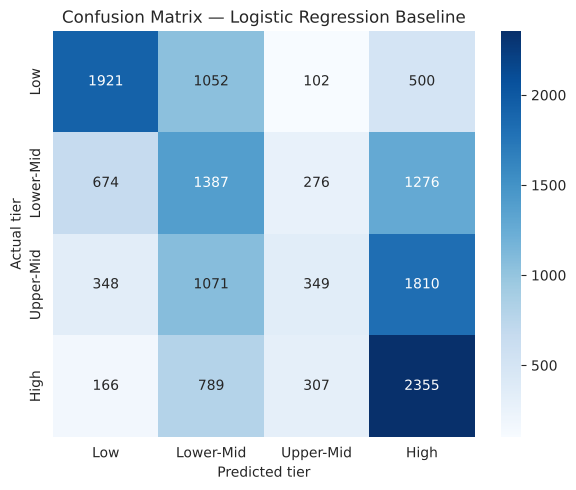

In [ ]:
cm = confusion_matrix(y_test, pred_clf, labels=["Low", "Lower-Mid", "Upper-Mid", "High"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low", "Lower-Mid", "Upper-Mid", "High"],
            yticklabels=["Low", "Lower-Mid", "Upper-Mid", "High"])
plt.xlabel("Predicted tier")
plt.ylabel("Actual tier")
plt.title("Confusion Matrix — Logistic Regression Baseline")
plt.tight_layout()
plt.show()

- Logistic Regression performs better than the Dummy baseline on every metric, showing that the features provide useful information for predicting salary tier.
- Most errors are between neighboring tiers rather than extreme tiers, which makes sense because salary is continuous and the tier cutoffs are somewhat arbitrary.
- `experience_level` and `role_family` likely contribute the most to the model, based on their strong relationship with salary seen earlier.

## Summary & next steps

What I covered:
- Documented every column, including `isco_group_hint` and its connection to the ILO's GenAI research.
- Found missing values in `isco_group_hint` and explained why they were not imputed.
- Checked categorical variables for imbalance and identified several heavily imbalanced features.
- Visualized salary by experience, role, work arrangement, and time, with a takeaway for each.
- Explored an exploratory join with the ILO's AI exposure scores.
- Removed data leakage from `salary`, `salary_currency`, and `salary_outlier_flag`, along with duplicate labels and high-cardinality job_title.
- Built a baseline model to predict four salary tiers using a leak-safe train/test split and reported accuracy, precision, recall, and F1.

Possible next steps:
- Try more salary tiers, such as deciles, or use salary as a continuous regression target.
- Add features like the ILO exposure score or frequency-encoded `employee_residence`.
- Test stronger models, such as Random Forest or Gradient Boosting.
- Check whether prediction errors are concentrated in certain roles or countries.

### Models
 -- I did my own labeling to make it easier for myself, so we can ignore the first half of the code.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
bins = [15000, 96000, 138750, 190200, 800000]

labels = [
    "Low",
    "Lower-Mid",
    "Upper-Mid",
    "High"]
df["salary_tier"] = pd.cut(
    df["salary_in_usd"],
    bins=bins,
    labels=labels,
    include_lowest=True)
print(df["salary_tier"].value_counts())
print(df["salary_tier"].value_counts(normalize=True))

salary_tier
High         17998
Low          17984
Lower-Mid    17978
Upper-Mid    17953
Name: count, dtype: int64
salary_tier
High         0.250275
Low          0.250080
Lower-Mid    0.249997
Upper-Mid    0.249649
Name: proportion, dtype: float64


In [ ]:
features = [
    "work_year",
    "experience_level",
    "employment_type",
    "employee_residence",
    "remote_ratio",
    "company_location",
    "company_size",
    "role_family"]
X = df[features].copy()
y = df["salary_tier"].copy()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nTraining class balance:")
print(y_train.value_counts(normalize=True))
print("\nTesting class balance:")
print(y_test.value_counts(normalize=True))

Training shape: (57530, 8)
Testing shape: (14383, 8)

Training class balance:
salary_tier
High         0.250269
Low          0.250078
Lower-Mid    0.249991
Upper-Mid    0.249661
Name: proportion, dtype: float64

Testing class balance:
salary_tier
High         0.250295
Low          0.250087
Lower-Mid    0.250017
Upper-Mid    0.249600
Name: proportion, dtype: float64


In [ ]:
categorical_features = [
    "experience_level",
    "employment_type",
    "employee_residence",
    "company_location",
    "company_size",
    "role_family"]
numerical_features = [
    "work_year",
    "remote_ratio"]

### Random Forest

-- Did random forest because it can help us with nonlinear relationships and the interaction between the salary, experience, location, role, and remote arrangement.

In [ ]:
results = []

In [ ]:
def evaluate(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true,
            y_pred,
            average="weighted"),
        "Recall": recall_score(
            y_true,
            y_pred,
            average="weighted"),
        "F1": f1_score(
            y_true,
            y_pred,
            average="weighted")}

In [ ]:
rf_pipeline = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1))])

rf_pipeline.fit(X_train, y_train)
pred_rf = rf_pipeline.predict(X_test)
results.append(
    evaluate("Random Forest", y_test, pred_rf))

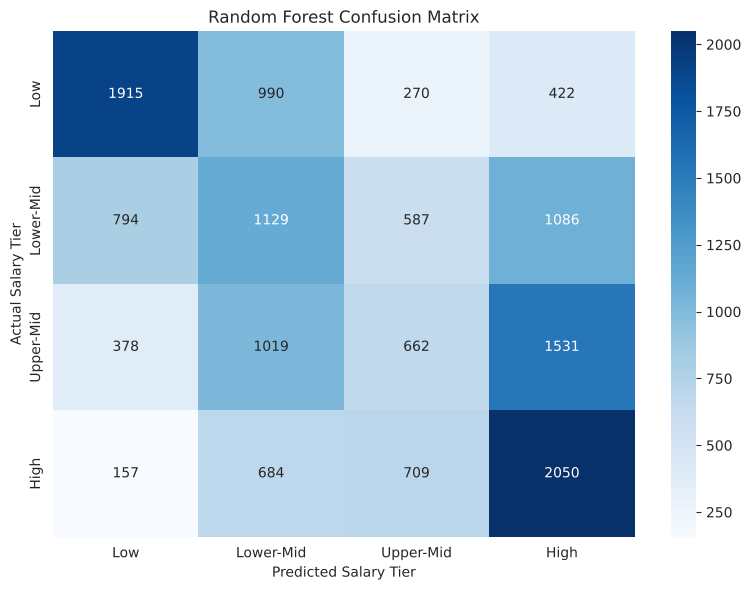

In [ ]:
labels = ["Low", "Lower-Mid", "Upper-Mid", "High"]

cm = confusion_matrix(
    y_test,
    pred_rf,
    labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels)

plt.xlabel("Predicted Salary Tier")
plt.ylabel("Actual Salary Tier")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

-- Confusion Matrix:

    - For the low category, Random Forest was able to get 53% correct (1924/3597). The worst area is the lower-mid category (974), showing it confuses it with the adjacent salary tier.
    - Lower-mid: it was correct 30% (1111/3597) of the time. When it came to the errors, it showed the largest jump in the high salary tier.
    - Upper-mid: 18% (672/3597) of the time it was correct; however, when it came to the errors made, it had some of the worst for high and lower mid, showing that it has a lot of struggles with differentiating between the three
    - High: Had the best results, correctly identified 57% (2056/3597), and most of their errors came from the upper-mid section. This suggests that for upper-mid and high salaries, the model likely overpredicts the high tier instead of the upper-mid category, which explains the high recall but low precision.

-- Based on the confusion matrix, the job characteristics provide some information about the salary tier, but they don't do well at distinguishing between middle salary tiers.

### Gradient Boosting

-- Went with gradient boosting because it is also a nonlinear model that can give us a comparison against the simple linear classifier and bagged tree-based model.

In [ ]:
gb_pipeline = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", GradientBoostingClassifier(
        random_state=42))])

gb_pipeline.fit(X_train, y_train)
pred_gb = gb_pipeline.predict(X_test)
results.append(
    evaluate("Gradient Boosting", y_test, pred_gb))

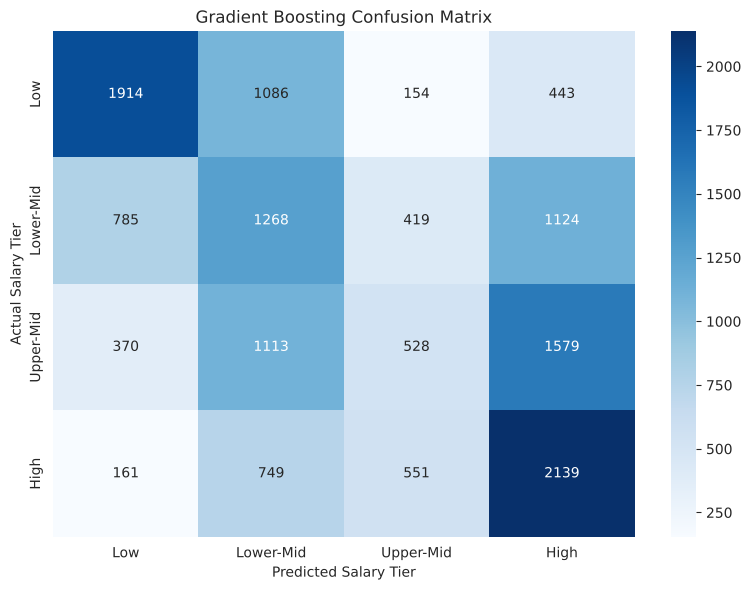

In [ ]:
cm = confusion_matrix(
    y_test,
    pred_gb,
    labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels)

plt.xlabel("Predicted Salary Tier")
plt.ylabel("Actual Salary Tier")
plt.title("Gradient Boosting Confusion Matrix")
plt.tight_layout()
plt.show()

### Logistic Regression + ILO Exposure

-- Adding ILO GenAI exposure score to the original features. This will help us see whether GenAI exposure can provide additional information about the salary tier.

In [ ]:
X_train_ai = X_train.copy()
X_test_ai = X_test.copy()

X_train_ai["gmyrek_exposure_score"] = df.loc[
    X_train_ai.index,
    "gmyrek_exposure_score"]
X_test_ai["gmyrek_exposure_score"] = df.loc[
    X_test_ai.index,
    "gmyrek_exposure_score"]

print("Training shape:", X_train_ai.shape)
print("Testing shape:", X_test_ai.shape)
print("\nTraining AI exposure missing:")
print(X_train_ai["gmyrek_exposure_score"].isna().sum())
print("\nTesting AI exposure missing:")
print(X_test_ai["gmyrek_exposure_score"].isna().sum())

Training shape: (57530, 9)
Testing shape: (14383, 9)

Training AI exposure missing:
32401

Testing AI exposure missing:
8139


> **Run-order fix (added):** the next cell uses `numerical_features_ai` / `categorical_features_ai`, which were only defined one cell later, so *Restart & Run All* crashed here. This added cell defines them first. The original cells are unchanged.

In [ ]:
categorical_features_ai = ["experience_level", "employment_type", "employee_residence",
                           "company_location", "company_size", "role_family"]
numerical_features_ai = ["work_year", "remote_ratio", "gmyrek_exposure_score"]

In [ ]:
numeric_transformer_ai = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True)),
    ("scaler", StandardScaler())])

categorical_transformer_ai = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocess_ai = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_ai, numerical_features_ai),
        ("cat", categorical_transformer_ai, categorical_features_ai)])

In [ ]:
categorical_features_ai = [
    "experience_level",
    "employment_type",
    "employee_residence",
    "company_location",
    "company_size",
    "role_family"]

numerical_features_ai = [
    "work_year",
    "remote_ratio",
    "gmyrek_exposure_score"]

preprocess_ai = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_ai, numerical_features_ai),
        ("cat", categorical_transformer_ai, categorical_features_ai)])

In [ ]:
logistic_ilo_pipeline = Pipeline(steps=[
    ("preprocess", preprocess_ai),
    ("model", LogisticRegression(max_iter=2000))])
logistic_ilo_pipeline.fit(X_train_ai, y_train)
pred_ilo = logistic_ilo_pipeline.predict(X_test_ai)

results.append(
    evaluate(
        "Logistic Regression + ILO Exposure",
        y_test,
        pred_ilo))

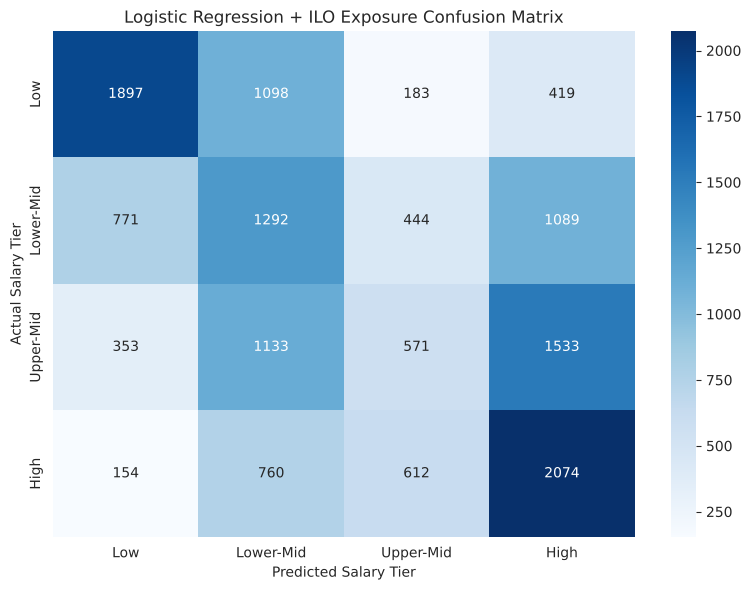

In [ ]:
cm = confusion_matrix(
    y_test,
    pred_ilo,
    labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels)

plt.xlabel("Predicted Salary Tier")
plt.ylabel("Actual Salary Tier")
plt.title("Logistic Regression + ILO Exposure Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
results_df = pd.DataFrame(results)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.400,0.396,0.400,0.391
1,Gradient Boosting,0.407,0.404,0.407,0.392
2,Logistic Regression + ILO Exposure,0.406,0.405,0.406,0.394


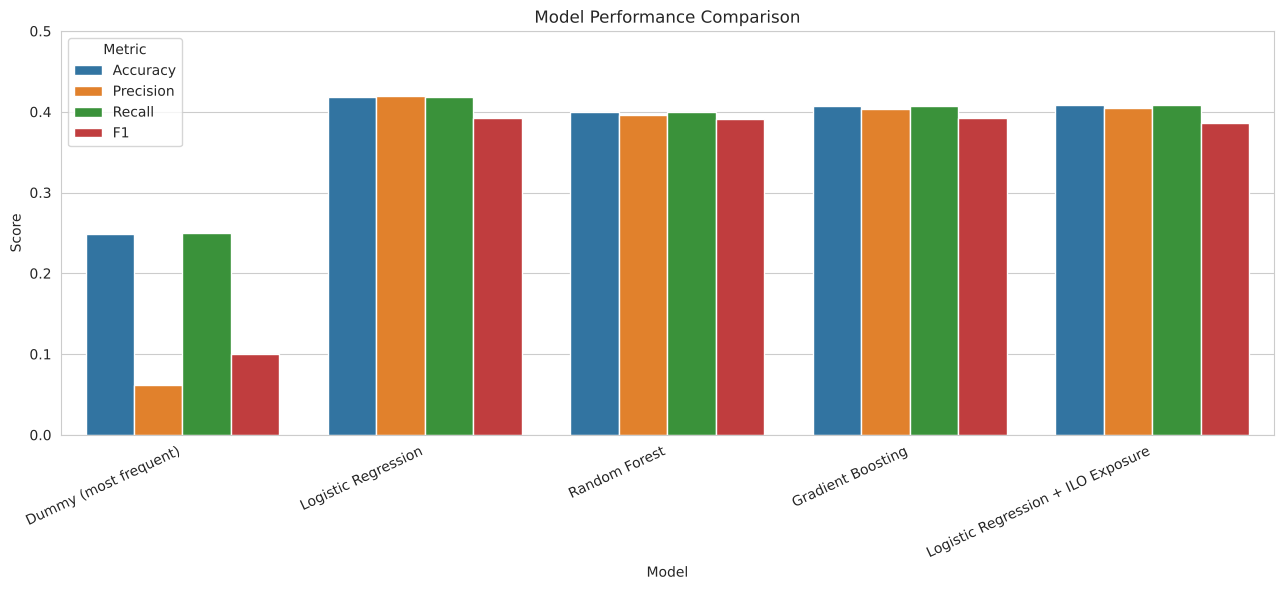

In [ ]:
performance_df = pd.DataFrame({
    "Model": [
        "Dummy (most frequent)",
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting",
        "Logistic Regression + ILO Exposure"],
    "Accuracy": [
        0.249,
        0.418,
        0.400,
        0.407,
        0.408],
    "Precision": [
        0.062,
        0.419,
        0.396,
        0.404,
        0.405],
    "Recall": [
        0.250,
        0.418,
        0.400,
        0.407,
        0.408],
    "F1": [
        0.100,
        0.392,
        0.391,
        0.392,
        0.386]})

performance_long = performance_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1"],
    var_name="Metric",
    value_name="Score")

plt.figure(figsize=(13, 6))
sns.barplot(
    data=performance_long,
    x="Model",
    y="Score",
    hue="Metric")
plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 0.5)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

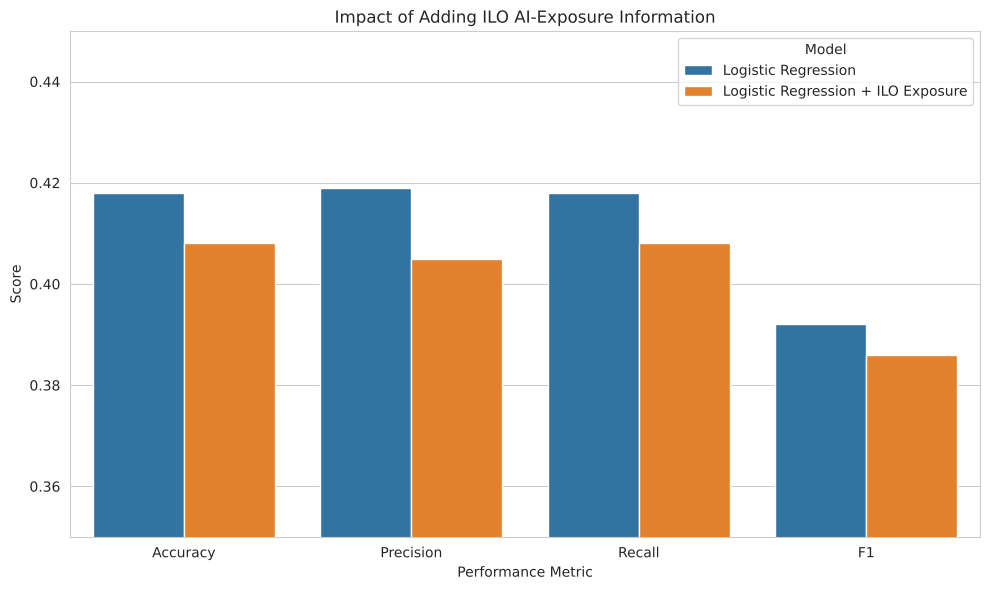

In [ ]:
ilo_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression + ILO Exposure"],
    "Accuracy": [0.418, 0.408],
    "Precision": [0.419, 0.405],
    "Recall": [0.418, 0.408],
    "F1": [0.392, 0.386]})

ilo_long = ilo_comparison.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1"],
    var_name="Metric",
    value_name="Score")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=ilo_long,
    x="Metric",
    y="Score",
    hue="Model")

plt.title("Impact of Adding ILO AI-Exposure Information")
plt.xlabel("Performance Metric")
plt.ylabel("Score")
plt.ylim(0.35, 0.45)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

### Comparison/Analysis

-- Results and Model Performance

    -- All of the models outperformed the dummy baseline. This could mean that the other features (employment, geographic, and occupational characteristics) contain useful information for the salary tiers.
    -- Based on the results, Logistic Regression had the best performance overall with 41.8% accuracy, 41.9% precision, 41.8% recall, and an F1 score of 0.392. Gradient Boosting produced a similar F1 score, but wasn't as good for the other metrics.
    -- This shows that the complex models didn't provide enough predictive benefit for the dataset.
    
-- Logistic Regression + ILO Exposure

    -- As for the Logis. Regre. + ILO Expo, it performed worst compared to the Logistic Regression without ILO, with all four metrics being slightly lower.
    -- This shows that adding the ILO GenAI exposure score didn't improve salary tier prediction in the dataset.
    -- This could be due to there only being five distinct exposure scores, possibly too many observations lacking an isco_group_hint, or salary being influenced by other factors.
    
-- Confusion Matrix

    -- Based on the confusion matrix, it shows that for all of the models, there was an issue with differentiating the salaries in the middle tiers compared to the low or high tiers. These results show that the easiest class for the models was the high salary class.
    -- Although AI exposure can have some relevance to salary differences across occupations, there isn't enough strong evidence to say that it is a direct cause of higher/lower salaries.

### Model selection:

Dummy → Logistic Regression → Random Forest → Gradient Boosting → Logistic + ILO

Validation:

    train/test split
    stratification
    four balanced salary tiers
    accuracy
    precision
    recall
    F1

---
# Part 4 — Modeling, Testing, Interpretation & Results

This part builds on the models above (Dummy → Logistic Regression → Random Forest → Gradient Boosting → Logistic + ILO). It does not replace them. It answers four questions:

1. **Testing:** how do *all* models compare when they are scored fairly, on the same held-out data with the same metrics?
2. **Diagnosis:** why do such different models all land near 0.41–0.42 accuracy?
3. **Better models:** what actually moves performance, and does the improvement hold up under stricter tests (bootstrap, cross-validation, future-year data)?
4. **Interpretation:** what drives the predictions, where does the model fail, and what does this say about GenAI exposure and pay?

| Section | Content |
|---|---|
| 4.1 | One split, one scorecard: fair re-evaluation of the earlier models (adds ROC-AUC and within-one-tier accuracy) |
| 4.2 | The information ceiling: why every earlier model ties |
| 4.3 | Improved models: adding the job title (keywords + TF-IDF) with LogReg and XGBoost |
| 4.4 | Alternative framing: predict log-salary, then convert to a tier |
| 4.5 | Final results on the held-out test set + ROC curves + confusion matrix |
| 4.6 | Robustness: 5-fold CV stability, paired bootstrap CI, train-on-past / test-on-2025 |
| 4.7 | Interpretation: permutation importance, SHAP, coefficients, worked examples |
| 4.8 | Error analysis: who the model gets wrong |
| 4.9 | The ILO GenAI exposure score, revisited |
| 4.10 | Results summary, slide talking points, limitations |

In [ ]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, mean_absolute_error)
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
TIERS = ["Low", "Lower-Mid", "Upper-Mid", "High"]
sns.set_style("whitegrid")

# Fresh copy of the data so Part 4 does not depend on variables modified earlier in the notebook
data = pd.read_csv("ai_jobs_salaries_clean.csv")
print(data.shape)

(71913, 17)


## 4.1 One split, one scorecard

The earlier models were scored in two different ways:
- the baseline used an unstratified split and **macro** metrics;
- RF, GB and Logistic + ILO used a different stratified split and **weighted** metrics.

As a result, the numbers in the earlier comparison table are not directly comparable.

Here **every model** uses the same setup:
- **One fixed split:** 80/20, stratified on salary quartile, `random_state=42`. The tier boundaries are computed from the **training salaries only** (as the baseline did) and then applied to the test set.
- **One scorecard:**
  - **Accuracy**
  - **Macro precision / recall / F1** (macro, so each tier counts equally)
  - **ROC-AUC (one-vs-rest, macro):** how well the predicted probabilities *rank* people into tiers. It is threshold-free and listed in the rubric's comparison table.
  - **Within-1-tier accuracy:** the tiers are *ordered*. Predicting Upper-Mid for a High earner is a much smaller mistake than predicting Low, so this counts predictions that are at most one tier away.

In [ ]:
train_df, test_df = train_test_split(
    data, test_size=0.2, random_state=RANDOM_STATE,
    stratify=pd.qcut(data["salary_in_usd"], 4, labels=False))

_, tier_edges = pd.qcut(train_df["salary_in_usd"], 4, retbins=True)   # TRAIN ONLY
cut_edges = tier_edges.copy(); cut_edges[0], cut_edges[-1] = -np.inf, np.inf

def to_tier(salary, edges=cut_edges):
    return pd.cut(pd.Series(salary), edges, labels=False).astype(int).values   # 0=Low ... 3=High

y_tr, y_te = to_tier(train_df["salary_in_usd"]), to_tier(test_df["salary_in_usd"])
print("Tier edges from train (USD):", tier_edges.round(0).tolist())
print(f"Train: {len(train_df):,} rows | Test: {len(test_df):,} rows")
print("Test tier balance:", dict(zip(TIERS, np.bincount(y_te) / len(y_te))))

Tier edges from train (USD): [15000.0, 96000.0, 138750.0, 190315.0, 800000.0]
Train: 57,530 rows | Test: 14,383 rows
Test tier balance: {'Low': np.float64(0.2500869081554613), 'Lower-Mid': np.float64(0.2500173816310923), 'Upper-Mid': np.float64(0.2499478551067232), 'High': np.float64(0.2499478551067232)}


In [ ]:
def scorecard(name, y_true, y_pred, y_proba=None):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "ROC-AUC (OvR)": roc_auc_score(y_true, y_proba, multi_class="ovr") if y_proba is not None else np.nan,
            "Within-1-tier": np.mean(np.abs(y_true - y_pred) <= 1)}

BASE_CAT = ["experience_level", "employment_type", "employee_residence",
            "company_location", "company_size", "role_family"]
BASE_NUM = ["work_year", "remote_ratio"]

def base_preprocess():
    # Same preprocessing as the earlier models
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), BASE_CAT),
                              ("num", StandardScaler(), BASE_NUM)])

earlier_models = {   # same model settings as used earlier in the notebook
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":   LogisticRegression(max_iter=2000),
    "Random Forest":         RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":     GradientBoostingClassifier(random_state=RANDOM_STATE),
}

results, fitted, probas, preds = [], {}, {}, {}
for name, est in earlier_models.items():
    t0 = time.time()
    pipe = Pipeline([("prep", base_preprocess()), ("model", est)]).fit(train_df, y_tr)
    fitted[name], probas[name], preds[name] = pipe, pipe.predict_proba(test_df), pipe.predict(test_df)
    results.append(scorecard(name, y_te, preds[name], probas[name]))
    print(f"{name:25s} trained in {time.time()-t0:5.1f}s")

pd.DataFrame(results).set_index("Model").round(3)

Dummy (most frequent)     trained in   0.2s


Logistic Regression       trained in   3.2s


Random Forest             trained in  32.2s


Gradient Boosting         trained in  12.2s


,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR),Within-1-tier
Model,,,,,,
Dummy (most frequent),0.250,0.063,0.250,0.100,0.500,0.500
Logistic Regression,0.417,0.417,0.417,0.403,0.685,0.792
Random Forest,0.411,0.408,0.411,0.399,0.678,0.787
Gradient Boosting,0.419,0.417,0.419,0.398,0.686,0.786


**Takeaway:** scored fairly, the three earlier models are **effectively tied**. Accuracy is about 0.42, macro F1 about 0.40 and ROC-AUC about 0.68–0.69. Moving from a linear model to bagged trees or boosting buys essentially nothing. Section 4.2 explains why.

## 4.2 The information ceiling: why every model ties

The 8 model features are almost all categorical, and they take few distinct values, so **many employees share exactly the same feature vector** but report very different salaries. When two rows have identical inputs, *no model* can give them different predictions. The best possible strategy for each group of identical rows is to predict that group's most common tier.

Applying that rule to every distinct feature combination gives an **upper bound on accuracy** for this feature set. We compute it on the training data, where it is optimistic because the rule memorises the training labels.

57,530 training rows collapse into only 2,201 distinct feature profiles.
Best earlier model, test accuracy:            0.419
Ceiling with the 8 original features (train): 0.428
Ceiling if job_title is also used (train):    0.490


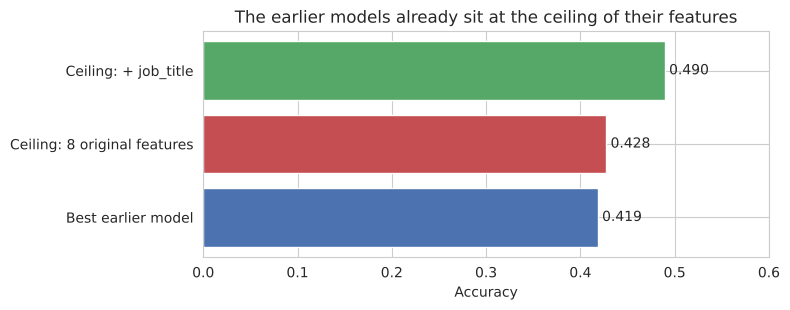

In [ ]:
model_cols = BASE_CAT + BASE_NUM

def ceiling(df, y, cols):
    # Accuracy if every identical feature combination is assigned its majority tier
    tmp = df[cols].copy(); tmp["_y"] = y
    return tmp.groupby(cols, dropna=False)["_y"].agg(lambda s: s.value_counts().iloc[0]).sum() / len(tmp)

n_profiles = len(train_df.drop_duplicates(subset=model_cols))
ceil_base = ceiling(train_df, y_tr, model_cols)
ceil_title = ceiling(train_df, y_tr, model_cols + ["job_title"])
best_earlier = max(r["Accuracy"] for r in results if not r["Model"].startswith("Dummy"))

print(f"{len(train_df):,} training rows collapse into only {n_profiles:,} distinct feature profiles.")
print(f"Best earlier model, test accuracy:            {best_earlier:.3f}")
print(f"Ceiling with the 8 original features (train): {ceil_base:.3f}")
print(f"Ceiling if job_title is also used (train):    {ceil_title:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(["Best earlier model", "Ceiling: 8 original features", "Ceiling: + job_title"],
               [best_earlier, ceil_base, ceil_title], color=["#4C72B0", "#C44E52", "#55A868"])
ax.bar_label(bars, fmt="%.3f", padding=3); ax.set_xlim(0, 0.6); ax.set_xlabel("Accuracy")
ax.set_title("The earlier models already sit at the ceiling of their features")
plt.tight_layout(); plt.show()

**This is the key diagnostic of the project.**

- Even a model that **memorised** the training labels could reach only about **0.43** accuracy with the 8 original features. The earlier models already reach about **0.42**. They are not under-fitted; they are **information-limited**. This is why RF, GB and LogReg tie, and why hyperparameter tuning would not help.
- To do better, the model needs **new information**, not a more complex algorithm.
- The richest unused column is the raw **`job_title`** (422 distinct titles). It was dropped earlier because `role_family` is derived from it, but that grouping discards most of the detail: 56% of rows become "Other / Unclassified". Adding the title raises the ceiling to about **0.49**.
- `job_title` is **not target leakage**. It is known before the salary is, since it appears on every job posting. It was dropped for redundancy, not because it reveals the salary.

## 4.3 Improved models: adding the job title

The title is used in two complementary ways:
- **Keyword flags:** `title_senior` (senior / sr / staff / principal / lead), `title_mgmt` (manager / director / head / VP / chief) and `title_junior` (junior / associate / intern / assistant). These are simple and interpretable.
- **TF-IDF on the full title** (single words and word pairs, `min_df=5`). This lets the model learn that, for example, "machine learning" or "research scientist" pays differently from "analyst" or "specialist", including inside the "Other" bucket.

The new features are used with two model families:
- **Logistic Regression**, which is fast, interpretable and handles the sparse TF-IDF features well;
- **XGBoost**, gradient-boosted trees that can capture interactions such as *US × Senior × ML title*.

**Which inputs help? Measured with 5-fold cross-validation on the training set only (test set untouched):**

In [ ]:
def add_title_features(d):
    d = d.copy(); t = d["job_title"].str.lower()
    d["title_senior"] = t.str.contains(r"\b(?:senior|sr|staff|principal|lead)\b").astype(int)
    d["title_mgmt"]   = t.str.contains(r"\b(?:manager|director|head|vp|vice president|chief)\b").astype(int)
    d["title_junior"] = t.str.contains(r"\b(?:junior|jr|associate|intern|assistant|trainee)\b").astype(int)
    return d

train_fe, test_fe = add_title_features(train_df), add_title_features(test_df)
KW = ["title_senior", "title_mgmt", "title_junior"]

def title_preprocess(keywords=True, tfidf=True):
    steps = [("cat", OneHotEncoder(handle_unknown="ignore"), BASE_CAT),
             ("num", StandardScaler(), BASE_NUM + (KW if keywords else []))]
    if tfidf:
        steps.append(("title", TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True), "job_title"))
    return ColumnTransformer(steps)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"acc": "accuracy", "f1": "f1_macro", "auc": "roc_auc_ovr"}

def cv_row(label, pipe, X=train_fe, y=y_tr):
    s = cross_validate(pipe, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
    return {"Inputs": label, "CV Accuracy": s["test_acc"].mean(), "CV F1 (macro)": s["test_f1"].mean(),
            "CV ROC-AUC": s["test_auc"].mean(), "F1 std across folds": s["test_f1"].std()}

LR = lambda: LogisticRegression(max_iter=4000)
feature_steps = pd.DataFrame([
    cv_row("1. Original 8 features",              Pipeline([("prep", base_preprocess()), ("model", LR())])),
    cv_row("2. + title keyword flags",            Pipeline([("prep", title_preprocess(True, False)), ("model", LR())])),
    cv_row("3. + title TF-IDF (full title text)", Pipeline([("prep", title_preprocess(True, True)), ("model", LR())])),
]).set_index("Inputs")
feature_steps.round(4)

,CV Accuracy,CV F1 (macro),CV ROC-AUC,F1 std across folds
Inputs,,,,
1. Original 8 features,0.4106,0.3949,0.6811,0.0094
2. + title keyword flags,0.4164,0.3925,0.6853,0.0058
3. + title TF-IDF (full title text),0.4408,0.4234,0.7105,0.0015


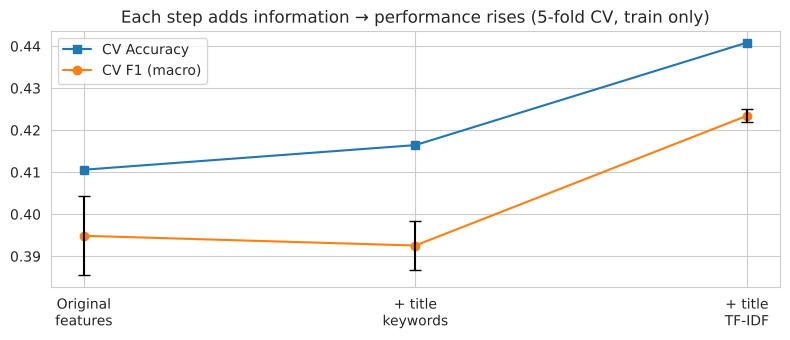

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(feature_steps))
for col, m in [("CV Accuracy", "s-"), ("CV F1 (macro)", "o-")]:
    ax.plot(x, feature_steps[col], m, label=col)
ax.errorbar(x, feature_steps["CV F1 (macro)"], yerr=feature_steps["F1 std across folds"], fmt="none", c="k", capsize=4)
ax.set_xticks(x); ax.set_xticklabels(["Original\nfeatures", "+ title\nkeywords", "+ title\nTF-IDF"])
ax.set_title("Each step adds information → performance rises (5-fold CV, train only)"); ax.legend()
plt.tight_layout(); plt.show()

The keyword flags help only slightly: accuracy and AUC rise a little but macro F1 does not, because few titles contain explicit seniority words (about 2% of rows). **TF-IDF on the full title is the big step**: +3 points of accuracy, +3 of macro F1 and +0.03 AUC. That gain is far larger than the fold-to-fold standard deviation, so it is not noise. Next, both model families are trained on the full feature set. The settings are fixed sensible defaults, not tuned, since 4.2 showed the bottleneck is information, not model capacity.

In [ ]:
new_models = {
    "LogReg + title features": LogisticRegression(max_iter=4000),
    "XGBoost + title features": XGBClassifier(n_estimators=400, learning_rate=0.08, max_depth=6,
                                              subsample=0.9, colsample_bytree=0.8, tree_method="hist",
                                              eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1),
}
for name, est in new_models.items():
    t0 = time.time()
    pipe = Pipeline([("prep", title_preprocess()), ("model", est)]).fit(train_fe, y_tr)
    fitted[name], probas[name], preds[name] = pipe, pipe.predict_proba(test_fe), pipe.predict(test_fe)
    print(f"{name:26s} trained in {time.time()-t0:5.1f}s")

LogReg + title features    trained in   6.2s


XGBoost + title features   trained in   9.5s


## 4.4 Alternative framing: predict log-salary, then convert to a tier

The tiers are cut from a continuous salary, so a 4-class classifier throws away information: it treats \$139K and \$190K as "the same", and \$190K and \$191K as "different". An alternative is to **regress log(salary)** with the same inputs and convert the predicted salary into a tier using the *same training edges*.

This approach:
- uses the full salary signal and respects the tier **order**, so it should make fewer "far-off" mistakes;
- also produces a **dollar estimate** with an interpretable error (MAE).

Ridge regression (L2-regularised linear regression) is used on the same features.

In [ ]:
ridge = Pipeline([("prep", title_preprocess()), ("model", Ridge(alpha=3.0))])
ridge.fit(train_fe, np.log(train_df["salary_in_usd"]))
ridge_salary = np.exp(ridge.predict(test_fe))
name = "Ridge log-salary → tier"
fitted[name], preds[name] = ridge, to_tier(ridge_salary)

mae_model = mean_absolute_error(test_df["salary_in_usd"], ridge_salary)
mae_naive = mean_absolute_error(test_df["salary_in_usd"], np.full(len(test_df), train_df["salary_in_usd"].median()))
print(f"Ridge MAE:                 ${mae_model:,.0f}")
print(f"Naive MAE (train median):  ${mae_naive:,.0f}   → {1 - mae_model/mae_naive:.0%} lower error")
print(f"Median absolute error:     ${np.median(np.abs(test_df['salary_in_usd'] - ridge_salary)):,.0f}")

Ridge MAE:                 $46,234
Naive MAE (train median):  $57,616   → 20% lower error
Median absolute error:     $34,386


## 4.5 Final results on the held-out test set

All models: same rows, same tier edges, same metrics.

In [ ]:
for name in new_models:
    results.append(scorecard(name, y_te, preds[name], probas[name]))
results.append(scorecard("Ridge log-salary → tier", y_te, preds["Ridge log-salary → tier"]))
final_df = pd.DataFrame(results).set_index("Model")
final_df.style.format("{:.3f}").highlight_max(axis=0, color="#cdeccd")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR),Within-1-tier
Model,,,,,,
Dummy (most frequent),0.250,0.063,0.250,0.100,0.500,0.500
Logistic Regression,0.417,0.417,0.417,0.403,0.685,0.792
Random Forest,0.411,0.408,0.411,0.399,0.678,0.787
Gradient Boosting,0.419,0.417,0.419,0.398,0.686,0.786
LogReg + title features,0.447,0.433,0.447,0.429,0.713,0.811
XGBoost + title features,0.444,0.427,0.444,0.425,0.714,0.812
Ridge log-salary → tier,0.405,0.480,0.405,0.404,nan,0.888


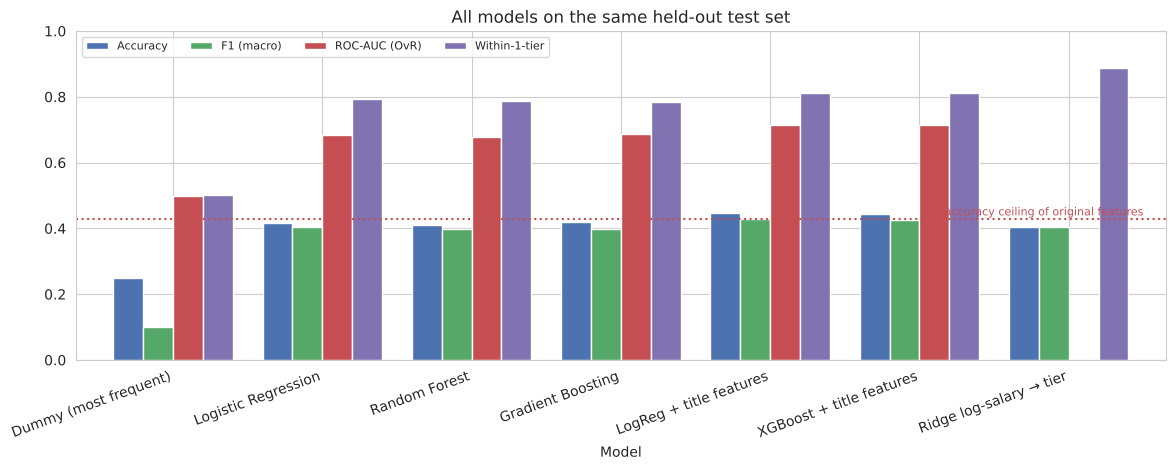

In [ ]:
plot_df = final_df[["Accuracy", "F1 (macro)", "ROC-AUC (OvR)", "Within-1-tier"]]
ax = plot_df.plot.bar(figsize=(12, 4.8), width=0.8, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
ax.axhline(ceil_base, ls=":", c="#C44E52", lw=1.5)
ax.text(len(plot_df) - 0.5, ceil_base + 0.012, "accuracy ceiling of original features", fontsize=8, color="#C44E52", ha="right")
ax.set_ylim(0, 1); ax.set_title("All models on the same held-out test set")
plt.xticks(rotation=20, ha="right"); plt.legend(loc="upper left", ncol=4, fontsize=8); plt.tight_layout(); plt.show()

Best classifier: LogReg + title features


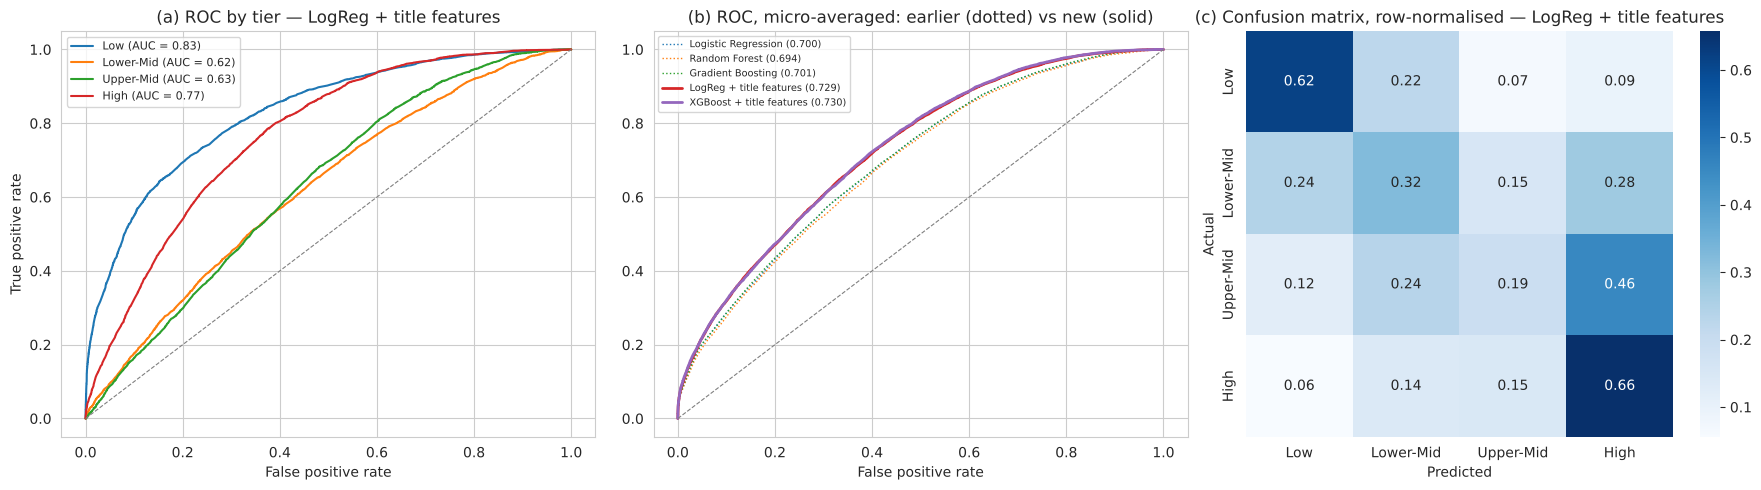

              precision    recall  f1-score   support

         Low      0.595     0.616     0.606      3597
   Lower-Mid      0.350     0.323     0.336      3596
   Upper-Mid      0.343     0.190     0.244      3595
        High      0.442     0.658     0.529      3595

    accuracy                          0.447     14383
   macro avg      0.433     0.447     0.429     14383
weighted avg      0.433     0.447     0.429     14383



In [ ]:
best_name = final_df.drop(index=["Ridge log-salary → tier"])["F1 (macro)"].idxmax()
print("Best classifier:", best_name)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
yb = label_binarize(y_te, classes=[0, 1, 2, 3])

# (a) ROC per tier for the best model
for k, tier in enumerate(TIERS):
    fpr, tpr, _ = roc_curve(yb[:, k], probas[best_name][:, k])
    axes[0].plot(fpr, tpr, label=f"{tier} (AUC = {roc_auc_score(yb[:, k], probas[best_name][:, k]):.2f})")
axes[0].plot([0, 1], [0, 1], c="grey", lw=0.8, ls="--")
axes[0].set_title(f"(a) ROC by tier — {best_name}"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend(fontsize=8)

# (b) micro-averaged ROC: earlier models vs new
for name in ["Logistic Regression", "Random Forest", "Gradient Boosting"] + list(new_models):
    fpr, tpr, _ = roc_curve(yb.ravel(), probas[name].ravel())
    axes[1].plot(fpr, tpr, lw=2 if name in new_models else 1, ls="-" if name in new_models else ":",
                 label=f"{name} ({roc_auc_score(yb.ravel(), probas[name].ravel()):.3f})")
axes[1].plot([0, 1], [0, 1], c="grey", lw=0.8, ls="--")
axes[1].set_title("(b) ROC, micro-averaged: earlier (dotted) vs new (solid)"); axes[1].set_xlabel("False positive rate"); axes[1].legend(fontsize=7)

# (c) confusion matrix
cm = confusion_matrix(y_te, preds[best_name], normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=TIERS, yticklabels=TIERS, ax=axes[2])
axes[2].set_title(f"(c) Confusion matrix, row-normalised — {best_name}"); axes[2].set_xlabel("Predicted"); axes[2].set_ylabel("Actual")
plt.tight_layout(); plt.show()

print(classification_report(y_te, preds[best_name], target_names=TIERS, digits=3))

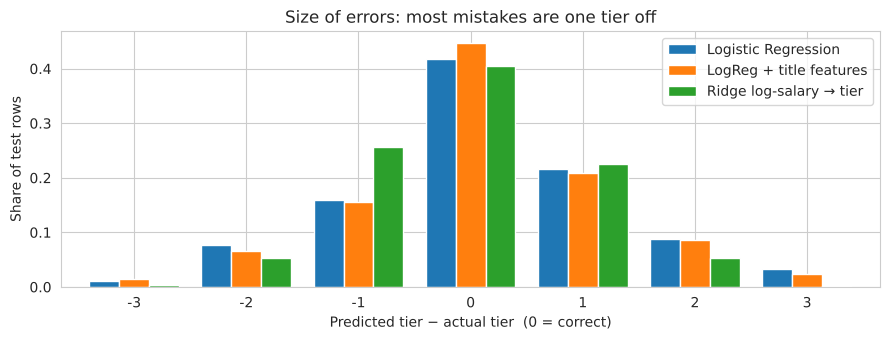

,-3,-2,-1,0,1,2,3
Logistic Regression,0.011,0.077,0.159,0.417,0.216,0.087,0.032
LogReg + title features,0.014,0.065,0.156,0.447,0.208,0.087,0.023
Ridge log-salary → tier,0.004,0.053,0.257,0.405,0.226,0.054,0.002


In [ ]:
# How far off are the mistakes? Distribution of (predicted tier - actual tier)
fig, ax = plt.subplots(figsize=(9, 3.5))
compare = ["Logistic Regression", best_name, "Ridge log-salary → tier"]
off = pd.DataFrame({m: pd.Series(preds[m] - y_te).value_counts(normalize=True) for m in compare}).reindex(range(-3, 4)).fillna(0)
off.plot.bar(ax=ax, width=0.8)
ax.set_xlabel("Predicted tier − actual tier  (0 = correct)"); ax.set_ylabel("Share of test rows")
ax.set_title("Size of errors: most mistakes are one tier off"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
off.round(3).T

**Reading the results**
- Adding the job title gives the first **real** improvement over the earlier models on every metric, including ROC-AUC. The improved models also **exceed the accuracy ceiling** the original features could ever reach.
- **LogReg and XGBoost perform about the same.** This again shows that the gain comes from *information*, not model complexity. The simpler, more interpretable Logistic Regression is a defensible final choice.
- **Low and High are the easiest tiers** (per-tier AUC about 0.83 and 0.77); **the two middle tiers are hard** (AUC about 0.62–0.63). Each middle tier is a narrow band (for example \$139K–\$190K) inside a very wide salary spread. The model often pushes Upper-Mid earners up into High: it recognises "well-paid profile" but cannot tell \$170K from \$210K.
- The **regression-then-tier** model has slightly lower exact accuracy but makes the **fewest two-or-more-tier mistakes**. For a salary-benchmarking use case that may be the better trade-off.

## 4.6 Robustness: is the improvement real?

A single test-set number can be lucky, so the improvement is checked three ways:
1. **5-fold cross-validation** on the training set: is performance stable across different data subsets?
2. **Paired bootstrap** on the test set: a 95% confidence interval for the gain over the earlier Logistic Regression.
3. **Temporal validation:** train on 2020–2024, test on 2025. This mimics real use, where you predict next year's salaries.

In [ ]:
cv_compare = pd.DataFrame([
    cv_row("Logistic Regression (original features)", Pipeline([("prep", base_preprocess()), ("model", LR())])),
    cv_row("LogReg + title features",                 Pipeline([("prep", title_preprocess()), ("model", LR())])),
    cv_row("XGBoost + title features", Pipeline([("prep", title_preprocess()), ("model", XGBClassifier(
        n_estimators=400, learning_rate=0.08, max_depth=6, subsample=0.9, colsample_bytree=0.8,
        tree_method="hist", eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=1))])),
]).set_index("Inputs")
cv_compare.index.name = "Model"
cv_compare.round(4)

,CV Accuracy,CV F1 (macro),CV ROC-AUC,F1 std across folds
Model,,,,
Logistic Regression (original features),0.4106,0.3949,0.6811,0.0094
LogReg + title features,0.4408,0.4234,0.7105,0.0015
XGBoost + title features,0.4410,0.4235,0.7108,0.0046


F1 (macro) gain of LogReg + title features over earlier LogReg: +0.026  95% CI [+0.019, +0.032]  share of resamples with no gain: 0.000
Accuracy   gain of LogReg + title features over earlier LogReg: +0.030  95% CI [+0.023, +0.036]  share of resamples with no gain: 0.000


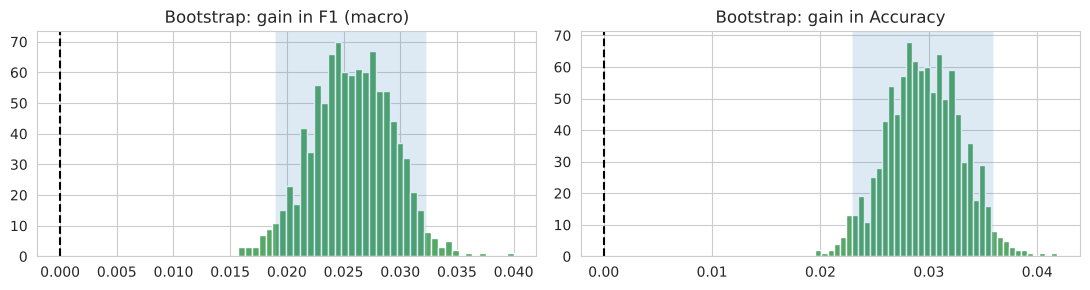

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
p_old, p_new = preds["Logistic Regression"], preds[best_name]
gains = {"F1 (macro)": [], "Accuracy": []}
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    gains["F1 (macro)"].append(f1_score(y_te[i], p_new[i], average="macro") - f1_score(y_te[i], p_old[i], average="macro"))
    gains["Accuracy"].append(accuracy_score(y_te[i], p_new[i]) - accuracy_score(y_te[i], p_old[i]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, (metric, g) in zip(axes, gains.items()):
    lo, hi = np.percentile(g, [2.5, 97.5])
    print(f"{metric:10s} gain of {best_name} over earlier LogReg: {np.mean(g):+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  "
          f"share of resamples with no gain: {np.mean(np.array(g) <= 0):.3f}")
    ax.hist(g, bins=40, color="#55A868"); ax.axvline(0, c="k", ls="--"); ax.axvspan(lo, hi, alpha=0.15)
    ax.set_title(f"Bootstrap: gain in {metric}")
plt.tight_layout(); plt.show()

In [ ]:
past, future = data[data["work_year"] <= 2024], data[data["work_year"] == 2025]
_, e_t = pd.qcut(past["salary_in_usd"], 4, retbins=True); e_t[0], e_t[-1] = -np.inf, np.inf
y_past, y_future = to_tier(past["salary_in_usd"], e_t), to_tier(future["salary_in_usd"], e_t)
past_fe, future_fe = add_title_features(past), add_title_features(future)
print(f"Train 2020–2024: {len(past):,} rows | Test 2025: {len(future):,} rows")
print("2025 tier mix using 2020–2024 edges:", dict(zip(TIERS, (np.bincount(y_future) / len(y_future)).round(3))))

temporal = []
for name, prep, Xa, Xb in [("Logistic Regression (original features)", base_preprocess(), past, future),
                           ("LogReg + title features", title_preprocess(), past_fe, future_fe)]:
    p = Pipeline([("prep", prep), ("model", LR())]).fit(Xa, y_past)
    temporal.append(scorecard(name, y_future, p.predict(Xb), p.predict_proba(Xb)))
temporal_df = pd.DataFrame(temporal).set_index("Model")
temporal_df.round(3)

Train 2020–2024: 33,631 rows | Test 2025: 38,282 rows
2025 tier mix using 2020–2024 edges: {'Low': np.float64(0.251), 'Lower-Mid': np.float64(0.257), 'Upper-Mid': np.float64(0.243), 'High': np.float64(0.25)}


,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR),Within-1-tier
Model,,,,,,
Logistic Regression (original features),0.409,0.420,0.406,0.351,0.68,0.752
LogReg + title features,0.440,0.424,0.439,0.395,0.71,0.780


**Robustness verdict**
- **CV:** the scores vary very little across folds (small standard deviation), and the ranking matches the test set.
- **Bootstrap:** the 95% confidence interval for the gain lies **entirely above zero**, so the improvement is not a lucky test split.
- **Future data:** trained only on 2020–2024, the model still predicts 2025 tiers at a similar level, and the title features still win. The model generalises forward in time and is not memorising one year. One caveat: salaries drift upward over time, so in practice the tier edges should be re-computed each year.

## 4.7 Interpretation: what drives the predictions?

### (a) Permutation importance: which *original* columns matter most?
We shuffle one input column at a time on the test set and measure how much macro F1 drops. The whole pipeline is evaluated, so every one-hot or TF-IDF column built from a raw column is shuffled together. This gives a fair importance per **original** column.

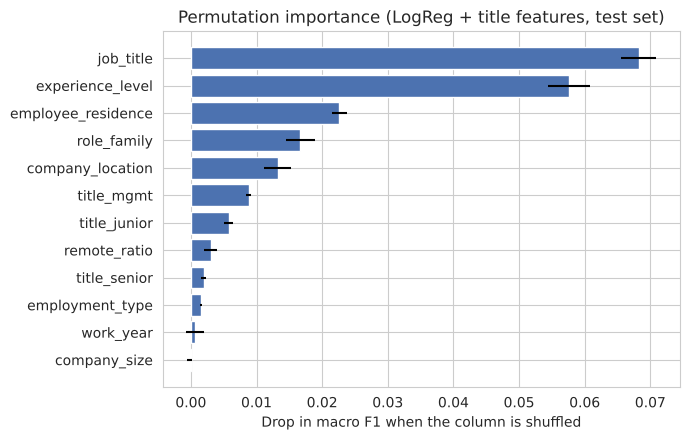

,mean,std
feature,,
job_title,0.0682,0.0027
experience_level,0.0576,0.0032
employee_residence,0.0226,0.0011
role_family,0.0167,0.0022
company_location,0.0133,0.0021
title_mgmt,0.0088,0.0004
title_junior,0.0057,0.0007
remote_ratio,0.0030,0.0010
title_senior,0.0020,0.0004


In [ ]:
interp_model = fitted["LogReg + title features"]
perm_cols = BASE_CAT + BASE_NUM + ["job_title"] + KW
X_perm = test_fe[perm_cols]
pi = permutation_importance(interp_model, X_perm, y_te, scoring="f1_macro",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": perm_cols, "mean": pi.importances_mean, "std": pi.importances_std}).sort_values("mean")
plt.figure(figsize=(7, 4.5))
plt.barh(imp["feature"], imp["mean"], xerr=imp["std"], color="#4C72B0")
plt.xlabel("Drop in macro F1 when the column is shuffled"); plt.title("Permutation importance (LogReg + title features, test set)")
plt.tight_layout(); plt.show()
imp.sort_values("mean", ascending=False).round(4).set_index("feature")

### (b) SHAP: how each feature pushes an individual prediction
SHAP values split each prediction into contributions from each input. Here we explain the XGBoost model's probability of the **High** tier on 2,000 test rows. Contributions from the many one-hot and TF-IDF columns are **summed back to their original column**, so the chart reads in plain terms.

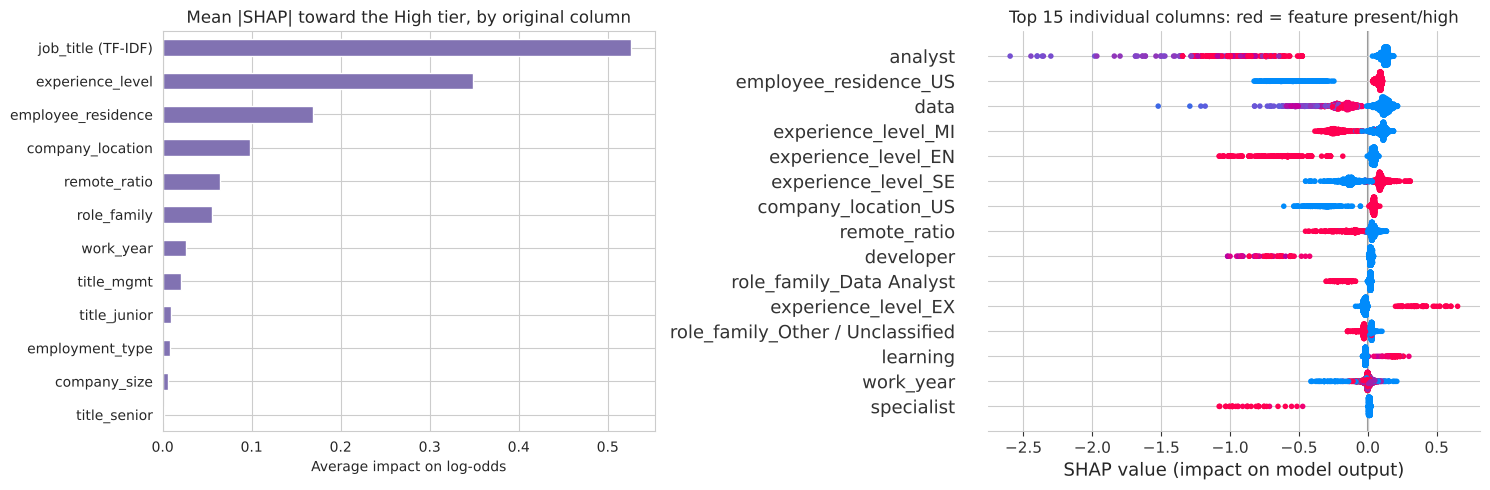

In [ ]:
xgb_pipe = fitted["XGBoost + title features"]
prep, booster = xgb_pipe.named_steps["prep"], xgb_pipe.named_steps["model"]
sample = test_fe.sample(2000, random_state=RANDOM_STATE)
X_sparse = prep.transform(sample)
X_s = X_sparse.toarray() if hasattr(X_sparse, "toarray") else np.asarray(X_sparse)
# XGBoost was trained on a sparse matrix, where zeros mean "missing". Pass NaN for those
# entries so the explainer sees exactly what the model saw (X_s is kept for plotting).
X_explain = np.where(X_s == 0, np.nan, X_s) if hasattr(X_sparse, "toarray") else X_s
feat_names = prep.get_feature_names_out()

explainer = shap.TreeExplainer(booster)
sv = explainer.shap_values(X_explain)
sv = np.asarray(sv)
sv_high = sv[:, :, 3] if sv.ndim == 3 else sv[3]    # contributions toward the High tier

def original_col(f):
    kind, rest = f.split("__", 1)
    if kind == "title": return "job_title (TF-IDF)"
    if kind == "cat":
        return next(c for c in BASE_CAT if rest.startswith(c + "_"))
    return rest

groups = pd.Series([original_col(f) for f in feat_names])
grouped = pd.DataFrame(sv_high, columns=feat_names).T.groupby(groups.values).sum().T
mean_abs = grouped.abs().mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
mean_abs.plot.barh(ax=axes[0], color="#8172B2")
axes[0].set_title("Mean |SHAP| toward the High tier, by original column"); axes[0].set_xlabel("Average impact on log-odds")

# Beeswarm-style view for the top one-hot / title columns
top_raw = pd.Series(np.abs(sv_high).mean(0), index=feat_names).nlargest(15).index
idx = [list(feat_names).index(f) for f in top_raw]
plt.sca(axes[1])
shap.summary_plot(sv_high[:, idx], X_s[:, idx], feature_names=[f.split("__", 1)[1] for f in top_raw],
                  show=False, plot_size=None, color_bar=False)
axes[1].set_title("Top 15 individual columns: red = feature present/high")
plt.tight_layout(); plt.show()

**Reading the SHAP plots**
- **The job title is the biggest single driver** of the High-tier prediction, followed by **experience level** and **where the employee lives / where the company is**. This matches the permutation importance in (a), even though it is computed on a different model (XGBoost vs LogReg) with a different method. Two independent methods agreeing makes the conclusion more trustworthy.
- In the right panel (red = the feature is present):
  - Titles containing **"analyst"**, **"specialist"**, **"developer"** or **"data"** (as in *Data Analyst / Data Specialist*) pull strongly away from High.
  - **"learning"** (as in *machine learning*) pushes toward High.
  - Being **US-based** pushes up, and being **non-US** pushes down, often by a large amount.
  - **Entry-level and mid-level** pull down, while **Senior and Executive** push up. Executive gives the largest upward pushes.
- `role_family` matters much less once the title is available, because the title contains the same information in finer detail.

### (c) Effect sizes: odds ratios from the Logistic Regression
For the interpretable LogReg we can read off how much each attribute changes the **odds of being in the High tier versus the Low tier**, holding the other inputs fixed.

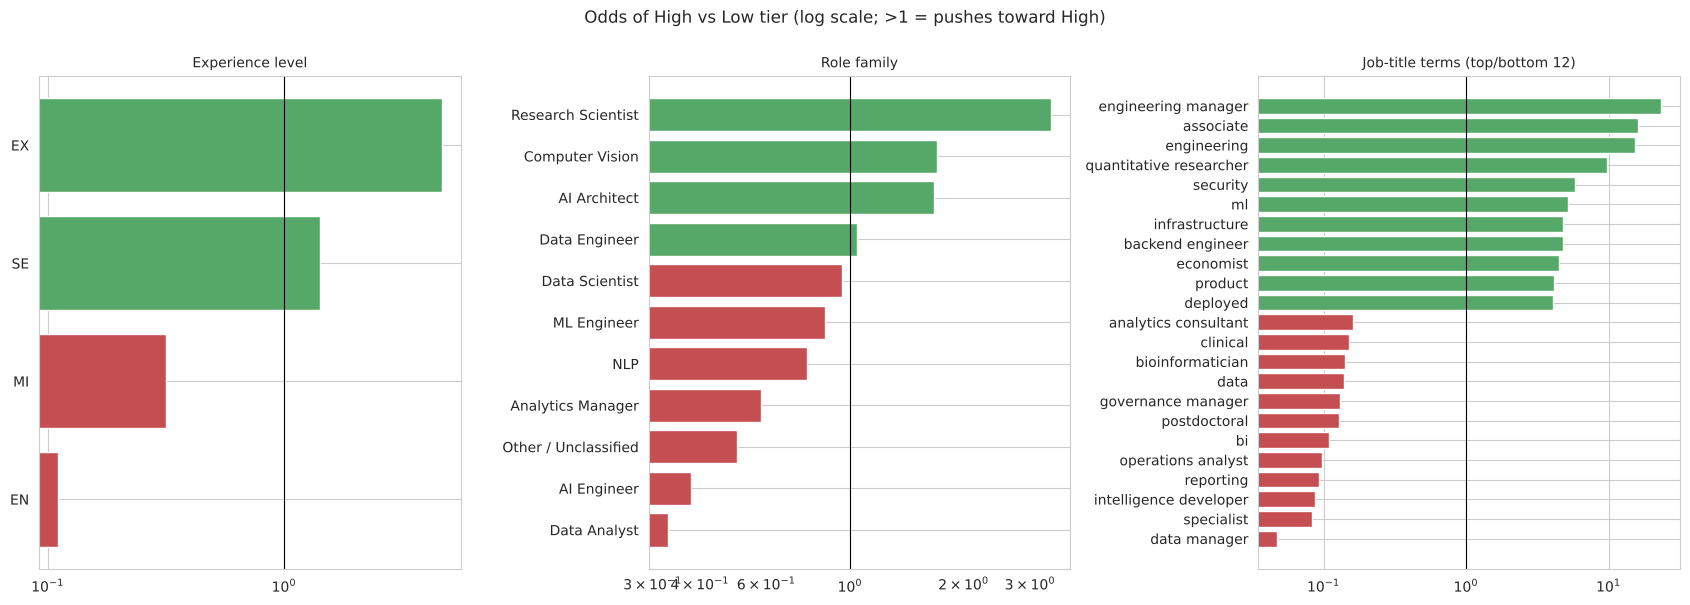

,% High when flag=1,% High when flag=0,rows with flag
title_senior,0.298,0.249,1210.0
title_mgmt,0.360,0.237,6230.0
title_junior,0.144,0.252,1261.0


In [ ]:
names = interp_model.named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame(interp_model.named_steps["model"].coef_.T, index=names, columns=TIERS)
odds_hl = np.exp(coef["High"] - coef["Low"]).rename("Odds ratio High vs Low")

def show(prefix, title, ax, top=None):
    s = odds_hl[odds_hl.index.str.startswith(prefix)]
    s.index = s.index.str.replace(prefix, "")
    if top: s = pd.concat([s.nlargest(top), s.nsmallest(top)]).drop_duplicates()
    s = s.sort_values()
    ax.barh(s.index, s.values, color=["#C44E52" if v < 1 else "#55A868" for v in s.values])
    ax.axvline(1, c="k", lw=0.8); ax.set_xscale("log"); ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
show("cat__experience_level_", "Experience level", axes[0])
show("cat__role_family_", "Role family", axes[1])
show("title__", "Job-title terms (top/bottom 12)", axes[2], top=12)
fig.suptitle("Odds of High vs Low tier (log scale; >1 = pushes toward High)", y=1.0)
plt.tight_layout(); plt.show()

kw = pd.DataFrame({k: {"% High when flag=1": (y_tr[train_fe[k] == 1] == 3).mean(),
                       "% High when flag=0": (y_tr[train_fe[k] == 0] == 3).mean(),
                       "rows with flag": int(train_fe[k].sum())} for k in KW}).T
kw.round(3)

**Reading the odds ratios**
- Experience is strongly ordered: Entry-level has much lower odds of High than Senior or Executive, holding everything else fixed.
- Once the title is in the model, role families such as Research Scientist and AI Architect still carry a premium.
- On the title side, engineering, ML, quantitative and infrastructure terms push toward High, while analyst, BI, reporting, specialist, clinical and postdoctoral terms push toward Low.
- Caveat: correlated inputs share credit. For example, "associate" appears as positive here because the `title_junior` flag, which already includes "associate", absorbs the negative effect, and the TF-IDF term then corrects it within specific titles. Read individual coefficients together with the keyword table below, not in isolation.

### (d) Worked examples: the model as a salary-tier estimator
Predicted tier probabilities for a few realistic profiles. This is a concrete way to show the model on a slide.

In [ ]:
profiles = pd.DataFrame([
    dict(job_title="Data Analyst", experience_level="EN", role_family="Data Analyst"),
    dict(job_title="Data Scientist", experience_level="MI", role_family="Data Scientist"),
    dict(job_title="Machine Learning Engineer", experience_level="SE", role_family="ML Engineer"),
    dict(job_title="Research Scientist", experience_level="SE", role_family="Research Scientist"),
    dict(job_title="Engineering Manager", experience_level="EX", role_family="Other / Unclassified"),
    dict(job_title="Machine Learning Engineer", experience_level="SE", role_family="ML Engineer",
         employee_residence="GB", company_location="GB"),
])
defaults = dict(work_year=2025, employment_type="FT", employee_residence="US", remote_ratio=0,
                company_location="US", company_size="M")
for k, v in defaults.items():
    profiles[k] = profiles[k].fillna(v) if k in profiles else v
profiles = add_title_features(profiles)
proba = pd.DataFrame(interp_model.predict_proba(profiles), columns=TIERS)
proba.index = [f"{r.job_title} · {r.experience_level} · {r.company_location}" for r in profiles.itertuples()]
proba["Ridge $ estimate"] = np.exp(ridge.predict(profiles)).round(-3)
proba.style.format({t: "{:.0%}" for t in TIERS} | {"Ridge $ estimate": "${:,.0f}"}).background_gradient(subset=TIERS, cmap="Greens", axis=1)

,Low,Lower-Mid,Upper-Mid,High,Ridge $ estimate
Data Analyst · EN · US,63%,25%,10%,2%,"$87,000"
Data Scientist · MI · US,23%,29%,26%,22%,"$134,000"
Machine Learning Engineer · SE · US,3%,14%,27%,56%,"$199,000"
Research Scientist · SE · US,3%,13%,27%,56%,"$204,000"
Engineering Manager · EX · US,0%,1%,12%,87%,"$320,000"
Machine Learning Engineer · SE · GB,27%,27%,19%,27%,"$123,000"


## 4.8 Error analysis: who does the model get wrong?

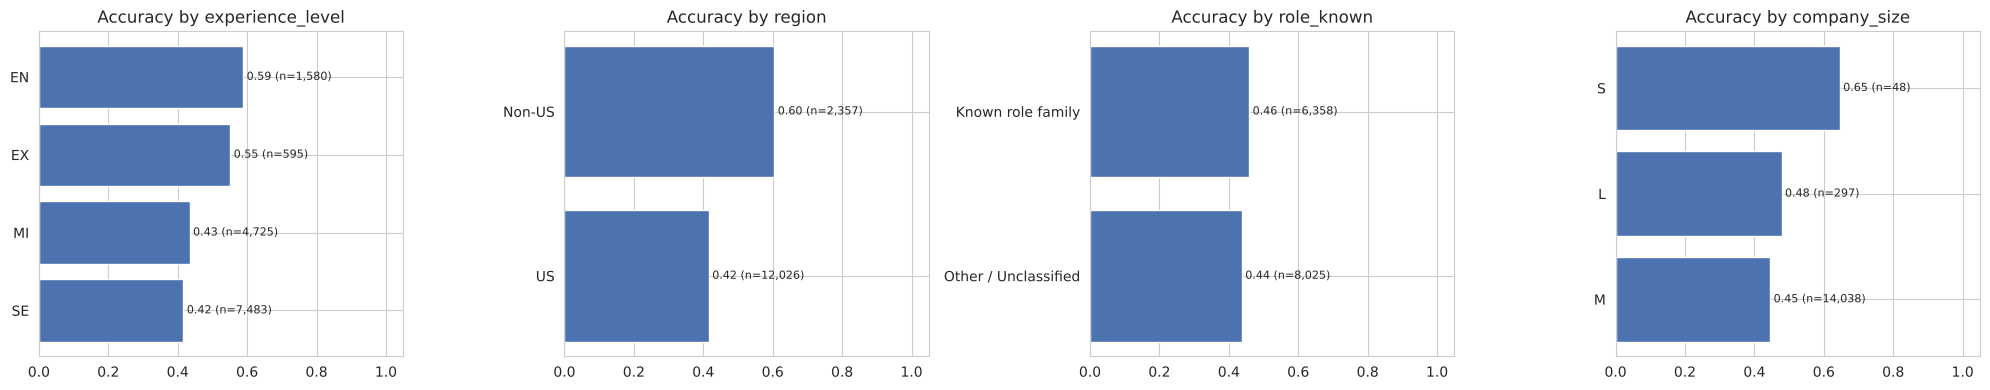

In [ ]:
err = test_fe.assign(actual=y_te, pred=preds[best_name], correct=(y_te == preds[best_name]),
                     abs_err=np.abs(test_df["salary_in_usd"].values - ridge_salary),
                     region=np.where(test_fe["company_location"] == "US", "US", "Non-US"),
                     role_known=np.where(test_fe["role_family"].str.startswith("Other"),
                                         "Other / Unclassified", "Known role family"))
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ["experience_level", "region", "role_known", "company_size"]):
    g = err.groupby(col)["correct"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(g.index, g["mean"], color="#4C72B0")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m + 0.01, i, f"{m:.2f} (n={n:,})", va="center", fontsize=8)
    ax.set_xlim(0, 1.05); ax.set_title(f"Accuracy by {col}")
plt.tight_layout(); plt.show()

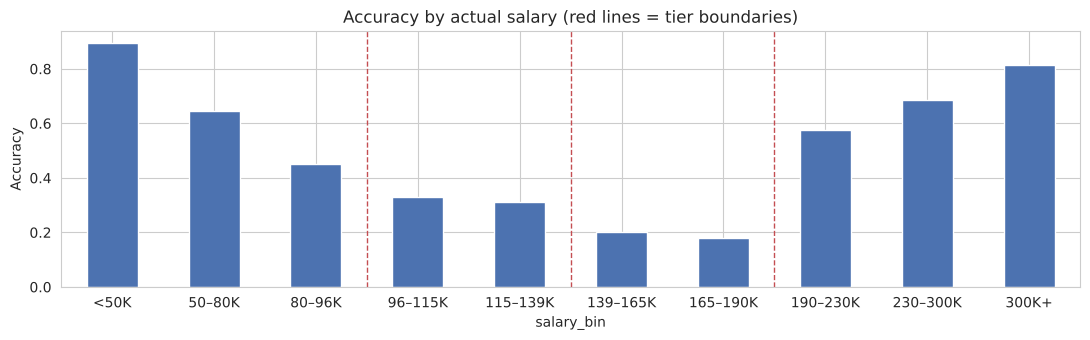

Most frequent job titles among the WORST Ridge dollar errors (top 5%):
job_title
Engineer                     75
Software Engineer            72
Machine Learning Engineer    67
Data Engineer                58
Manager                      56
Data Scientist               56
Research Scientist           33
Data Analyst                 27


In [ ]:
# Which actual salaries are hardest? Accuracy across the salary range
err["salary"] = test_df["salary_in_usd"].values
err["salary_bin"] = pd.cut(err["salary"], bins=[0, 50e3, 80e3, 96e3, 115e3, 139e3, 165e3, 190e3, 230e3, 300e3, 1e7],
                           labels=["<50K", "50–80K", "80–96K", "96–115K", "115–139K", "139–165K",
                                   "165–190K", "190–230K", "230–300K", "300K+"])
g = err.groupby("salary_bin", observed=True)["correct"].mean()
fig, ax = plt.subplots(figsize=(11, 3.5))
g.plot.bar(ax=ax, color="#4C72B0")
for edge_pos in [2.5, 4.5, 6.5]:
    ax.axvline(edge_pos, c="#C44E52", ls="--", lw=1)
ax.set_ylabel("Accuracy"); ax.set_title("Accuracy by actual salary (red lines = tier boundaries)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

print("Most frequent job titles among the WORST Ridge dollar errors (top 5%):")
worst = err[err["abs_err"] >= err["abs_err"].quantile(0.95)]
print(worst["job_title"].value_counts().head(8).to_string())

**What the errors tell us**
- **Accuracy is U-shaped across the salary range.** It is about 0.9 below \$50K and about 0.8 above \$300K, but only about 0.2–0.3 in the \$96K–\$190K middle tiers. Those tiers are narrow bands in the densest part of the distribution. Someone at \$137K versus \$141K is "Lower-Mid" versus "Upper-Mid", a distinction no feature can reliably make. This is a property of turning a continuous target into bins, not a model bug, and it is why the within-1-tier metric matters.
- **Entry-level and executive roles are easier** (about 0.59 and 0.55 accuracy) than mid-level and senior roles (about 0.42–0.43), where most rows fall into the crowded middle.
- **Non-US rows are easier.** In USD terms most non-US salaries simply fall into "Low", so the country nearly decides the tier. The hard problem is ranking **US** salaries.
- **"Other / Unclassified" roles** are where the title features help most, because for them `role_family` carries no information.
- The **largest dollar errors** come from generic titles such as "Engineer" or "Manager", where the same title covers anything from a junior to a director. That noise is irreducible without more data, such as company or seniority details.

## 4.9 The ILO GenAI exposure score, revisited

Earlier, adding the ILO exposure score did not improve Logistic Regression. This section shows **why**, which turns a null result into a finding.

In [ ]:
gmyrek_scores = {
    "Information and communications technology service managers": 0.440,
    "Mathematicians, actuaries and statisticians": 0.561,
    "Software and applications developers": 0.527,
    "Business services and administration managers": 0.419,
    "Physical and earth science professionals": 0.411}
expo = data["isco_group_hint"].map(gmyrek_scores)
print("Number of distinct exposure values within each role_family:")
print(expo.groupby(data["role_family"]).nunique(dropna=False).to_string())
print(f"\nRows with an exposure score: {expo.notna().mean():.0%}")

tr_ilo = train_fe.assign(exposure=train_df["isco_group_hint"].map(gmyrek_scores).fillna(-1),
                         has_exposure=train_df["isco_group_hint"].notna().astype(int))
ilo_prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), BASE_CAT),
                              ("num", StandardScaler(), BASE_NUM + KW + ["exposure", "has_exposure"]),
                              ("title", TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True), "job_title")])
ilo_cv = pd.DataFrame([
    cv_row("LogReg + title features", Pipeline([("prep", title_preprocess()), ("model", LR())]), tr_ilo),
    cv_row("LogReg + title features + ILO exposure", Pipeline([("prep", ilo_prep), ("model", LR())]), tr_ilo),
]).set_index("Inputs")
ilo_cv.round(4)

Number of distinct exposure values within each role_family:
role_family
AI Architect            1
AI Engineer             1
Analytics Manager       1
Computer Vision         1
Data Analyst            1
Data Engineer           1
Data Scientist          1
ML Engineer             1
NLP                     1
Other / Unclassified    1
Research Scientist      1

Rows with an exposure score: 44%


,CV Accuracy,CV F1 (macro),CV ROC-AUC,F1 std across folds
Inputs,,,,
LogReg + title features,0.4408,0.4234,0.7105,0.0015
LogReg + title features + ILO exposure,0.4409,0.4232,0.7105,0.0015


- Every role family maps to **exactly one** exposure value. The exposure score is therefore just a **re-labelling of `role_family`**, which the model already sees as one-hot columns. It cannot add information, and the cross-validated scores with and without it are effectively identical.
- It covers less than half the rows, since every "Other / Unclassified" row has no score.
- **What this means for the research question:** this dataset **cannot** tell us whether GenAI exposure affects pay, because exposure never varies *within* a role. A proper test would need exposure assigned at the **4-digit ISCO occupation level, matched from each raw `job_title`**. That is a concrete next step, and the TF-IDF title features already show how much signal the titles contain.

## 4.10 Results summary & slide talking points

**1. Fair comparison.** On one split with one metric suite, the earlier models (LogReg, RF, GB) are tied: accuracy about 0.42, ROC-AUC about 0.68–0.69. The Dummy baseline sits at 0.25.

**2. Diagnosis.** The 8 original features collapse about 57K training rows into a couple of thousand identical profiles. The **best possible** accuracy with them is about 0.43, and the earlier models already reach it. The problem was missing information, not the choice of model.

**3. Improvement.** Adding the **job title** (keyword flags + TF-IDF) is the only change that moves every metric: accuracy, macro F1, ROC-AUC and within-1-tier. It pushes performance **above** the old ceiling. LogReg ≈ XGBoost, so the simpler and interpretable LogReg is the recommended final model.

**4. Robustness.** The gain is stable across 5 CV folds, has a 95% bootstrap CI above zero, and holds when training on 2020–2024 and predicting 2025.

**5. Alternative framing.** Regressing log-salary and then binning gives the fewest large (two-tier) mistakes plus a dollar estimate, a good option if far-off errors are costly.

**6. Interpretation.**
- Country (US vs not), experience level and job-title terms dominate the predictions.
- Title terms such as "engineering manager", "quantitative researcher", "ML", "infrastructure" and "backend engineer" push toward High; "analyst", "BI", "reporting", "specialist" and "postdoctoral" push toward Low.
- Errors cluster at the tier boundaries and among generic titles.

**7. ILO exposure.** It is a 1-to-1 function of `role_family`, so it carries no extra signal here. Testing the GenAI–pay link needs occupation-level exposure matched from titles (future work).

**Limitations:**
- Salaries are self-reported.
- About 84% of rows are US-based.
- Tier bins hide large within-tier variation.
- Titles are free text and inconsistent across companies.
- Tier edges drift with salary growth.

**Future work:**
- Map titles to 4-digit ISCO codes so exposure can vary within roles.
- Try ordinal models that respect tier order (e.g. cumulative-link / CORAL).
- Normalise non-US salaries for cost of living.